# TAAC Robust Re-Experiment Notebook V3

Notebook ini untuk memperbaiki eksperimen sebelum penulisan ulang paper ke **Theoretical and Applied Climatology**.

Judul target:

**Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework**

Fokus perbaikan:
1. menjaga dataset tetap konsisten dengan paper utama;
2. tidak download ulang Himawari jika file lokal sudah ada;
3. menyimpan/memuat checkpoint `X_train`, `X_val`, `X_test`, dan mask;
4. threshold sensitivity dengan metrik aman dari overflow;
5. fair ablation: semua varian memakai validation-selected constrained threshold dan full-image test evaluation;
6. external precipitation validation hanya jika data eksternal benar-benar tersedia;
7. export tabel/figure/ringkasan siap masuk paper.

In [1]:
# ============================================================
# 0. OPTIONAL INSTALL
# ============================================================

# Jalankan hanya jika library belum tersedia.
# !pip install numpy pandas matplotlib scikit-learn opencv-python pillow tqdm tensorflow openpyxl


In [2]:
# ============================================================
# 1. IMPORTS, SEED, GPU
# ============================================================

import os, re, gc, json, math, time, random, warnings, shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image
import cv2

from sklearn.metrics import precision_recall_curve, auc

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass
    print("GPU detected:", gpus)
else:
    print("No GPU detected. Running on CPU.")

print("Imports ready.")


No GPU detected. Running on CPU.
Imports ready.


In [3]:
# ============================================================
# 2. MAIN CONFIGURATION
# ============================================================

BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

MAIN_OUTPUT_DIR = (
    BASE_DIR
    / "outputs"
    / "ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2"
    / "jma_snapshot_20260529_0126UTC"
)

TAAC_OUTPUT_DIR = BASE_DIR / "outputs" / "TAAC_reexperiment_v3"
TABLES_DIR = TAAC_OUTPUT_DIR / "tables"
FIGURES_DIR = TAAC_OUTPUT_DIR / "figures"
MODELS_DIR = TAAC_OUTPUT_DIR / "models"
CACHE_DIR = TAAC_OUTPUT_DIR / "cache"
CHECKPOINT_DIR = BASE_DIR / "taac_checkpoints_v3"
EXTERNAL_PRECIP_DIR = BASE_DIR / "external_precip_validation"

for d in [TAAC_OUTPUT_DIR, TABLES_DIR, FIGURES_DIR, MODELS_DIR, CACHE_DIR, CHECKPOINT_DIR, EXTERNAL_PRECIP_DIR]:
    d.mkdir(parents=True, exist_ok=True)

INPUT_PRODUCTS = ["b13", "b08", "b07", "b03"]
TARGET_PRODUCT = "hrp"
SEQ_LEN = 4
IMG_SIZE = 256
PATCH_SIZE = 128
BATCH_SIZE = 8
BASE_FILTERS = 24
LEARNING_RATE = 7e-4

RUN_THRESHOLD_SENSITIVITY = True
RUN_FAIR_ABLATION = True
RUN_EXTERNAL_PRECIP_VALIDATION = True
RUN_EVENT_CASE_ANALYSIS = True

TRAIN_MISSING_ABLATIONS = True
RETRAIN_ABLATIONS = False
EPOCHS_ABLATION = 40
ABLATION_PATIENCE = 10

EXPECTED_TEST_POS_RATIO = 0.0253
POS_RATIO_TOLERANCE = 0.0100

THRESHOLD_VALUES = np.round(np.arange(0.05, 0.951, 0.01), 4)
RATIO_LOWER_MULT = 0.50
RATIO_UPPER_MULT = 2.00

PAPER_TITLE_TAAC = (
    "Himawari-derived heavy rainfall potential segmentation over Indonesia "
    "using an imbalance-aware spatiotemporal deep learning framework"
)

print("BASE_DIR:", BASE_DIR)
print("MAIN_OUTPUT_DIR:", MAIN_OUTPUT_DIR)
print("TAAC_OUTPUT_DIR:", TAAC_OUTPUT_DIR)


BASE_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program
MAIN_OUTPUT_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC
TAAC_OUTPUT_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3


## 3. Cache-safe Himawari data handling

Cell ini opsional. Gunakan untuk mengganti cell download lama.  
Jika manifest/file lokal sudah valid, tidak ada download ulang.

In [4]:
# ============================================================
# 3. CACHE-SAFE HIMAWARI R2W DATA HANDLING
# ============================================================

from urllib.parse import urljoin
import requests
from bs4 import BeautifulSoup

if "DATASET_TAG" not in globals():
    DATASET_TAG = "jma_snapshot_20260529_0126UTC"

if "RAW_DIR" not in globals():
    RAW_DIR = BASE_DIR / "dataset_himawari_r2w" / "raw"

if "MANIFEST_DIR" not in globals():
    MANIFEST_DIR = BASE_DIR / "dataset_himawari_r2w" / "manifests"

if "DOWNLOAD_PRODUCTS" not in globals():
    DOWNLOAD_PRODUCTS = ["b13", "b08", "b07", "b03", "hrp", "snd"]

if "MAX_TIMES" not in globals():
    MAX_TIMES = None

if "JMA_LIST_URL" not in globals():
    JMA_LIST_URL = ""

if "JMA_ROOT_URL" not in globals():
    JMA_ROOT_URL = "https://www.jma.go.jp/bosai/himawari/data/"

USE_LOCAL_CACHE = True
FORCE_PARSE_JMA_LIST = False
OVERWRITE_DOWNLOAD = False

manifest_path = MANIFEST_DIR / f"manifest_{DATASET_TAG}.csv"


def safe_get(url, timeout=60, retries=3, sleep_sec=2):
    if not url:
        raise RuntimeError("JMA_LIST_URL belum diisi. Gunakan parser dari notebook utama atau isi URL JMA yang benar.")
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=timeout)
            r.raise_for_status()
            return r
        except Exception as e:
            last_err = e
            print(f"[Retry {attempt}/{retries}] gagal akses {url}: {e}")
            time.sleep(sleep_sec)
    raise RuntimeError(f"Gagal akses setelah {retries} percobaan: {url}") from last_err


def is_valid_jpeg(path):
    path = Path(path)
    if (not path.exists()) or path.stat().st_size < 1024:
        return False
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img is not None and img.size > 0


def validate_manifest_files(manifest, products):
    if manifest is None or manifest.empty:
        return False

    required_cols = ["time_code"] + list(products)
    missing_cols = [c for c in required_cols if c not in manifest.columns]
    if missing_cols:
        print("Manifest tidak lengkap. Kolom hilang:", missing_cols)
        return False

    flags = []
    for _, row in manifest.iterrows():
        ok = True
        for product in products:
            fp = Path(str(row[product]))
            if not is_valid_jpeg(fp):
                ok = False
                break
        flags.append(ok)

    print(f"Validasi manifest lokal: {sum(flags)}/{len(flags)} timestamp valid.")
    return len(flags) > 0 and sum(flags) == len(flags)


def load_existing_manifest_if_valid(manifest_path, products):
    manifest_path = Path(manifest_path)
    if not manifest_path.exists():
        return None
    try:
        manifest = pd.read_csv(manifest_path)
        if validate_manifest_files(manifest, products):
            print("Manifest lokal valid. Download dilewati.")
            return manifest.reset_index(drop=True)
        print("Manifest ditemukan tetapi ada file hilang/rusak.")
    except Exception as e:
        print("Gagal membaca manifest lokal:", e)
    return None


def extract_time_code_from_filename(path, product):
    name = Path(path).name.lower()
    pattern = re.compile(rf"r2w_{re.escape(product.lower())}_(\d{{4}})\.jpg$")
    m = pattern.search(name)
    return None if not m else m.group(1)


def build_local_manifest_from_raw(raw_dir, products):
    raw_dir = Path(raw_dir)
    product_maps = {}
    for product in products:
        product_dir = raw_dir / product
        product_maps[product] = {}
        if not product_dir.exists():
            continue
        for fp in sorted(product_dir.glob(f"r2w_{product}_*.jpg")):
            time_code = extract_time_code_from_filename(fp, product)
            if time_code and is_valid_jpeg(fp):
                product_maps[product][time_code] = str(fp)

    common_times = None
    for product in products:
        times = set(product_maps.get(product, {}).keys())
        common_times = times if common_times is None else common_times.intersection(times)

    if not common_times:
        print("Tidak ada timestamp lokal lengkap untuk semua produk.")
        return pd.DataFrame()

    common_times = sorted(common_times)
    if MAX_TIMES is not None:
        common_times = common_times[:int(MAX_TIMES)]

    rows = []
    for time_code in common_times:
        row = {"time_code": time_code}
        ok = True
        for product in products:
            fp = product_maps[product].get(time_code)
            row[product] = fp
            row[f"{product}_url"] = ""
            if fp is None or not is_valid_jpeg(fp):
                ok = False
        row["is_complete_and_valid"] = ok
        rows.append(row)

    manifest = pd.DataFrame(rows).sort_values("time_code").reset_index(drop=True)
    print("Manifest lokal dibangun dari RAW_DIR:", len(manifest), "timestamp.")
    return manifest


def prepare_manifest_cache_safe():
    MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
    RAW_DIR.mkdir(parents=True, exist_ok=True)

    manifest = None
    if USE_LOCAL_CACHE and not FORCE_PARSE_JMA_LIST:
        manifest = load_existing_manifest_if_valid(manifest_path, DOWNLOAD_PRODUCTS)

    if manifest is None and USE_LOCAL_CACHE and not FORCE_PARSE_JMA_LIST:
        local_manifest = build_local_manifest_from_raw(RAW_DIR, DOWNLOAD_PRODUCTS)
        if not local_manifest.empty and validate_manifest_files(local_manifest, DOWNLOAD_PRODUCTS):
            manifest = local_manifest.copy()
            manifest.to_csv(manifest_path, index=False)
            print("Manifest baru dibuat dari file lokal:", manifest_path)

    if manifest is None:
        raise RuntimeError(
            "Data lokal belum lengkap. Untuk menghindari salah download, jalankan cell download asli dari notebook utama "
            "atau isi JMA_LIST_URL yang benar pada cell konfigurasi."
        )

    valid_manifest = manifest[manifest["is_complete_and_valid"]].reset_index(drop=True)
    if valid_manifest.empty:
        raise RuntimeError("Tidak ada file valid. Cek folder RAW_DIR/manifest.")

    print("Manifest saved/used:", manifest_path)
    print("Valid timestamps:", len(valid_manifest))
    display(valid_manifest.head())
    return valid_manifest

# Jalankan hanya jika ingin cek/membuat manifest lokal:
# valid_manifest = prepare_manifest_cache_safe()


## 4. Checkpoint data split

Bagian ini adalah kunci agar eksperimen tidak error lagi setelah kernel restart.  
Setelah notebook utama berhasil sampai temporal split, jalankan `taac_save_array_checkpoints()`.

In [5]:
# ============================================================
# 4A. SAVE DATA SPLIT CHECKPOINT
# ============================================================

def taac_save_array_checkpoints():
    required = ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]
    missing = [v for v in required if v not in globals()]
    if missing:
        raise RuntimeError("Belum bisa save checkpoint. Variabel hilang: " + ", ".join(missing))

    for name in required:
        np.save(CHECKPOINT_DIR / f"{name}.npy", globals()[name])

    for name in ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"]:
        if name in globals():
            np.save(CHECKPOINT_DIR / f"{name}.npy", globals()[name])

    for name in ["meta_train", "meta_val", "meta_test"]:
        if name in globals() and isinstance(globals()[name], pd.DataFrame):
            globals()[name].to_csv(CHECKPOINT_DIR / f"{name}.csv", index=False)

    print("Array checkpoints saved to:", CHECKPOINT_DIR)

# Jalankan setelah split/patch selesai:
# taac_save_array_checkpoints()


In [6]:
# ============================================================
# 4B. LOAD DATA SPLIT CHECKPOINT
# ============================================================

def taac_load_array_checkpoints(required_patch=False):
    required = ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]
    missing_files = []
    for name in required:
        path = CHECKPOINT_DIR / f"{name}.npy"
        if not path.exists():
            missing_files.append(str(path))

    if missing_files:
        raise FileNotFoundError(
            "Checkpoint array belum lengkap. Jalankan notebook utama sampai split, "
            "lalu jalankan taac_save_array_checkpoints(). Missing: " + "; ".join(missing_files)
        )

    for name in required:
        globals()[name] = np.load(CHECKPOINT_DIR / f"{name}.npy")

    for name in ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"]:
        path = CHECKPOINT_DIR / f"{name}.npy"
        if path.exists():
            globals()[name] = np.load(path)

    for name in ["meta_train", "meta_val", "meta_test"]:
        path = CHECKPOINT_DIR / f"{name}.csv"
        if path.exists():
            globals()[name] = pd.read_csv(path)

    if required_patch:
        missing_patch = [n for n in ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"] if n not in globals()]
        if missing_patch:
            raise RuntimeError("Patch checkpoint belum ada: " + ", ".join(missing_patch))

    print("Array checkpoints loaded.")
    for name in required:
        print(name, globals()[name].shape, "positive_ratio=", float(np.mean(globals()[name])))

# Jika kernel restart, jalankan:
# taac_load_array_checkpoints(required_patch=False)


In [7]:
# ============================================================
# 4C. AUTO LOAD CHECKPOINT IF CORE VARIABLES ARE MISSING
# ============================================================

core_vars = ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]
missing_core = [v for v in core_vars if v not in globals()]

if missing_core:
    print("Core variables belum ada di memory:", missing_core)
    try:
        taac_load_array_checkpoints(required_patch=False)
    except Exception as e:
        print("Auto-load checkpoint gagal:", e)
        print("Solusi:")
        print("1. Jalankan notebook utama sampai temporal split dan patch creation.")
        print("2. Jalankan taac_save_array_checkpoints().")
        print("3. Buka ulang notebook ini dan jalankan dari cell ini.")
else:
    print("Core variables tersedia di memory.")
    for name in core_vars:
        print(name, globals()[name].shape, "positive_ratio=", float(np.mean(globals()[name])))


Core variables belum ada di memory: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']
Array checkpoints loaded.
X_train (97, 4, 256, 256, 4) positive_ratio= 0.23859602212905884
y_train (97, 256, 256, 1) positive_ratio= 0.0025357904378324747
X_val (21, 4, 256, 256, 4) positive_ratio= 0.21148152649402618
y_val (21, 256, 256, 1) positive_ratio= 0.0032137916423380375
X_test (21, 4, 256, 256, 4) positive_ratio= 0.20828251540660858
y_test (21, 256, 256, 1) positive_ratio= 0.0042717345058918


In [8]:
# ============================================================
# 5. DATASET INTEGRITY CHECK
# ============================================================

def taac_dataset_integrity_report():
    required = ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]
    missing = [v for v in required if v not in globals()]
    if missing:
        raise RuntimeError("Variabel dataset belum tersedia: " + ", ".join(missing))

    rows = []
    for split, X_arr, y_arr in [
        ("train", X_train, y_train),
        ("validation", X_val, y_val),
        ("test", X_test, y_test),
    ]:
        rows.append({
            "split": split,
            "n_sequences": int(len(X_arr)),
            "X_shape": str(X_arr.shape),
            "y_shape": str(y_arr.shape),
            "positive_pixel_ratio": float(np.mean(y_arr)),
            "min_y": float(np.min(y_arr)),
            "max_y": float(np.max(y_arr)),
        })

    df = pd.DataFrame(rows)
    out_path = TABLES_DIR / "dataset_integrity_report.csv"
    df.to_csv(out_path, index=False)
    display(df)
    print("Saved:", out_path)

    test_ratio = float(np.mean(y_test))
    diff = abs(test_ratio - EXPECTED_TEST_POS_RATIO)

    if diff > POS_RATIO_TOLERANCE:
        print("=" * 80)
        print("WARNING: Test positive-pixel ratio tidak konsisten dengan paper utama.")
        print("Expected sekitar:", EXPECTED_TEST_POS_RATIO)
        print("Current :", test_ratio)
        print("Diff    :", diff)
        print("JANGAN gunakan hasil eksperimen ini untuk paper sebelum dataset/mask/split disamakan.")
        print("=" * 80)
    else:
        print("Dataset integrity OK. Test positive-pixel ratio masih konsisten dengan paper utama.")

    return df

integrity_df = taac_dataset_integrity_report()


,split,n_sequences,X_shape,y_shape,positive_pixel_ratio,min_y,max_y
0,train,97,"(97, 4, 256, 256, 4)","(97, 256, 256, 1)",0.002536,0.0,1.0
1,validation,21,"(21, 4, 256, 256, 4)","(21, 256, 256, 1)",0.003214,0.0,1.0
2,test,21,"(21, 4, 256, 256, 4)","(21, 256, 256, 1)",0.004272,0.0,1.0


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\dataset_integrity_report.csv
Expected sekitar: 0.0253
Current : 0.0042717345058918
Diff    : 0.0210282654941082
JANGAN gunakan hasil eksperimen ini untuk paper sebelum dataset/mask/split disamakan.


In [9]:
# ============================================================
# 6. SAFE METRICS AND FAIR THRESHOLD SELECTION
# ============================================================

def binary_metrics_np(y_true, y_prob, threshold=0.5):
    yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)

    yp_prob = np.asarray(y_prob).reshape(-1).astype(np.float32)
    yp_prob = np.nan_to_num(yp_prob, nan=0.0, posinf=1.0, neginf=0.0)
    yp_prob = np.clip(yp_prob, 0.0, 1.0)

    if yt.shape[0] != yp_prob.shape[0]:
        raise ValueError(f"Shape mismatch: y_true={yt.shape}, y_prob={yp_prob.shape}")

    yp = (yp_prob >= float(threshold)).astype(np.uint8)

    tp = int(np.count_nonzero((yt == 1) & (yp == 1)))
    fp = int(np.count_nonzero((yt == 0) & (yp == 1)))
    fn = int(np.count_nonzero((yt == 1) & (yp == 0)))
    tn = int(np.count_nonzero((yt == 0) & (yp == 0)))

    tp_f, fp_f, fn_f, tn_f = map(float, [tp, fp, fn, tn])
    eps = 1e-7

    precision = tp_f / (tp_f + fp_f + eps)
    recall = tp_f / (tp_f + fn_f + eps)
    specificity = tn_f / (tn_f + fp_f + eps)
    fpr = fp_f / (fp_f + tn_f + eps)
    dice = (2.0 * tp_f) / (2.0 * tp_f + fp_f + fn_f + eps)
    iou = tp_f / (tp_f + fp_f + fn_f + eps)
    accuracy = (tp_f + tn_f) / (tp_f + tn_f + fp_f + fn_f + eps)
    balanced_accuracy = 0.5 * (recall + specificity)

    denom = (tp_f + fp_f) * (tp_f + fn_f) * (tn_f + fp_f) * (tn_f + fn_f)
    if denom <= 0:
        mcc = 0.0
    else:
        mcc = ((tp_f * tn_f) - (fp_f * fn_f)) / (math.sqrt(denom) + eps)

    return {
        "threshold": float(threshold),
        "iou": float(iou),
        "dice_f1": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "fpr": float(fpr),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(balanced_accuracy),
        "mcc": float(mcc),
        "actual_positive_ratio": float(yt.mean()),
        "predicted_positive_ratio": float(yp.mean()),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }


def pr_auc_score_np(y_true, y_prob):
    yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)
    yp = np.asarray(y_prob).reshape(-1).astype(np.float32)
    yp = np.nan_to_num(yp, nan=0.0, posinf=1.0, neginf=0.0)
    yp = np.clip(yp, 0.0, 1.0)
    if len(np.unique(yt)) < 2:
        return np.nan
    precision, recall, _ = precision_recall_curve(yt, yp)
    return float(auc(recall, precision))


def select_threshold_constrained_fair(
    y_true,
    y_prob,
    model_name="model",
    threshold_values=THRESHOLD_VALUES,
    lower_mult=RATIO_LOWER_MULT,
    upper_mult=RATIO_UPPER_MULT,
):
    actual_ratio = float((np.asarray(y_true).reshape(-1) >= 0.5).mean())
    rows = []

    for th in threshold_values:
        m = binary_metrics_np(y_true, y_prob, threshold=float(th))
        pred_ratio = m["predicted_positive_ratio"]
        ratio_penalty = abs(np.log((pred_ratio + 1e-7) / (actual_ratio + 1e-7)))

        m["model"] = model_name
        m["positive_ratio_penalty"] = float(ratio_penalty)
        m["is_ratio_valid"] = bool(
            (pred_ratio >= lower_mult * actual_ratio) and
            (pred_ratio <= upper_mult * actual_ratio)
        )

        m["selection_score"] = (
            m["iou"]
            + 0.20 * m["dice_f1"]
            + 0.10 * m["balanced_accuracy"]
            + 0.10 * m["mcc"]
            - 0.025 * ratio_penalty
        )
        rows.append(m)

    df = pd.DataFrame(rows)
    valid = df[df["is_ratio_valid"]].copy()

    if len(valid) > 0:
        best_idx = valid["selection_score"].idxmax()
    else:
        best_idx = df["selection_score"].idxmax()

    best_th = float(df.loc[best_idx, "threshold"])
    return best_th, df


def predict_full(model, X_arr, input_type="sequence", batch_size=BATCH_SIZE, verbose=0):
    if input_type == "2d_last_frame":
        return model.predict(X_arr[:, -1, ...], batch_size=batch_size, verbose=verbose)
    return model.predict(X_arr, batch_size=batch_size, verbose=verbose)


def predict_with_cache(model, X_arr, cache_name, input_type="sequence", force=False):
    cache_path = CACHE_DIR / f"{cache_name}.npy"
    if cache_path.exists() and not force:
        arr = np.load(cache_path)
        print("Loaded prediction cache:", cache_path)
        return arr
    pred = predict_full(model, X_arr, input_type=input_type, batch_size=BATCH_SIZE, verbose=1)
    pred = np.asarray(pred, dtype=np.float32)
    np.save(cache_path, pred)
    print("Saved prediction cache:", cache_path)
    return pred

print("Safe metrics ready.")


Safe metrics ready.


In [10]:
# ============================================================
# 7. LOSS FUNCTIONS, DATASET BUILDER, FALLBACK ST-HRPNET BUILDER
# ============================================================

SMOOTH = 1e-6

if "LOSS_POS_WEIGHT" not in globals():
    source_y = globals().get("y_train_patch", globals().get("y_train", None))
    if source_y is not None:
        pos_ratio = float(np.mean(source_y))
        neg_ratio = 1.0 - pos_ratio
        LOSS_POS_WEIGHT = min(max(neg_ratio / (pos_ratio + 1e-7), 1.0), 20.0)
    else:
        LOSS_POS_WEIGHT = 8.0

print("LOSS_POS_WEIGHT:", LOSS_POS_WEIGHT)


def dice_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * inter + SMOOTH) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + SMOOTH)


def iou_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - inter
    return (inter + SMOOTH) / (union + SMOOTH)


def weighted_bce_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-6, 1.0 - 1e-6)
    bce = keras.backend.binary_crossentropy(y_true, y_pred)
    weights = y_true * LOSS_POS_WEIGHT + (1.0 - y_true)
    return tf.reduce_mean(bce * weights)


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def false_positive_penalty(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    bg = 1.0 - y_true
    return tf.reduce_sum(bg * y_pred) / (tf.reduce_sum(bg) + SMOOTH)


def combined_hrp_loss(y_true, y_pred):
    return 0.60 * weighted_bce_loss(y_true, y_pred) + 0.35 * dice_loss(y_true, y_pred) + 0.05 * false_positive_penalty(y_true, y_pred)


def combined_hrp_loss_no_fp(y_true, y_pred):
    return 0.65 * weighted_bce_loss(y_true, y_pred) + 0.35 * dice_loss(y_true, y_pred)


def precision_at_05(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin)
    return (tp + SMOOTH) / (tp + fp + SMOOTH)


def recall_at_05(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin))
    return (tp + SMOOTH) / (tp + fn + SMOOTH)


def compile_model_with_loss(model, loss_fn="with_fp", lr=1e-4):
    if loss_fn == "no_fp":
        loss = combined_hrp_loss_no_fp
    elif loss_fn == "bce":
        loss = "binary_crossentropy"
    else:
        loss = combined_hrp_loss

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=loss,
        metrics=[dice_coef, iou_coef, precision_at_05, recall_at_05],
    )
    return model


def make_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False):
    X_arr = np.asarray(X_arr, dtype=np.float32)
    y_arr = np.asarray(y_arr, dtype=np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(X_arr), 2048), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def conv2d_block(x, filters, name, dropout=0.0):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)
    if dropout and dropout > 0:
        x = layers.Dropout(dropout, name=f"{name}_drop")(x)
    return x


def td_conv_block(x, filters, name, dropout=0.0):
    x = layers.TimeDistributed(layers.Conv2D(filters, 3, padding="same", use_bias=False), name=f"{name}_td_conv1")(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_td_bn1")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_td_relu1")(x)
    x = layers.TimeDistributed(layers.Conv2D(filters, 3, padding="same", use_bias=False), name=f"{name}_td_conv2")(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_td_bn2")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_td_relu2")(x)
    if dropout and dropout > 0:
        x = layers.TimeDistributed(layers.Dropout(dropout), name=f"{name}_td_drop")(x)
    return x


def last_time_step(x):
    return x[:, -1, ...]


def fallback_build_st_hrpnet_v1_patchbalanced(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inputs = keras.Input(shape=(seq_len, None, None, n_channels), name="himawari_sequence_dynamic")

    x1 = td_conv_block(inputs, base, "enc1", dropout=0.03)
    p1 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool1")(x1)

    x2 = td_conv_block(p1, base * 2, "enc2", dropout=0.05)
    p2 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool2")(x2)

    x3 = td_conv_block(p2, base * 4, "enc3", dropout=0.08)
    p3 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool3")(x3)

    z = layers.ConvLSTM2D(base * 8, 3, padding="same", return_sequences=False, name="convlstm_bottleneck")(p3)
    z = layers.BatchNormalization(name="bottleneck_bn")(z)
    z = conv2d_block(z, base * 8, "bottleneck_refine", dropout=0.10)

    s3 = layers.Lambda(last_time_step, name="skip3_last")(x3)
    s2 = layers.Lambda(last_time_step, name="skip2_last")(x2)
    s1 = layers.Lambda(last_time_step, name="skip1_last")(x1)

    d3 = layers.UpSampling2D((2, 2), name="up3")(z)
    d3 = layers.Concatenate(name="concat3")([d3, s3])
    d3 = conv2d_block(d3, base * 4, "dec3", dropout=0.08)

    d2 = layers.UpSampling2D((2, 2), name="up2")(d3)
    d2 = layers.Concatenate(name="concat2")([d2, s2])
    d2 = conv2d_block(d2, base * 2, "dec2", dropout=0.05)

    d1 = layers.UpSampling2D((2, 2), name="up1")(d2)
    d1 = layers.Concatenate(name="concat1")([d1, s1])
    d1 = conv2d_block(d1, base, "dec1", dropout=0.03)

    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_probability")(d1)
    return keras.Model(inputs, outputs, name="ST_HRPNet_v1_PatchBalanced")


if "build_st_hrpnet_v1_patchbalanced" not in globals():
    build_st_hrpnet_v1_patchbalanced = fallback_build_st_hrpnet_v1_patchbalanced
    print("Using fallback ST-HRPNet builder.")
else:
    print("Using existing ST-HRPNet builder from main notebook.")

print("Losses/model helpers ready.")


LOSS_POS_WEIGHT: 20.0
Using fallback ST-HRPNet builder.
Losses/model helpers ready.


In [11]:
# ============================================================
# 7. LOSS FUNCTIONS, DATASET BUILDER, EXACT ST-HRPNET BUILDER
# ============================================================

SMOOTH = 1e-6

if "LOSS_POS_WEIGHT" not in globals():
    source_y = globals().get("y_train_patch", globals().get("y_train", None))
    if source_y is not None:
        pos_ratio = float(np.mean(source_y))
        neg_ratio = 1.0 - pos_ratio
        LOSS_POS_WEIGHT = min(max(neg_ratio / (pos_ratio + 1e-7), 1.0), 20.0)
    else:
        LOSS_POS_WEIGHT = 6.815723822580276

print("LOSS_POS_WEIGHT:", LOSS_POS_WEIGHT)


def dice_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * inter + SMOOTH) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + SMOOTH
    )


def iou_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - inter
    return (inter + SMOOTH) / (union + SMOOTH)


def weighted_bce_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-6, 1.0 - 1e-6)
    bce = keras.backend.binary_crossentropy(y_true, y_pred)
    weights = y_true * LOSS_POS_WEIGHT + (1.0 - y_true)
    return tf.reduce_mean(bce * weights)


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def false_positive_penalty(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    bg = 1.0 - y_true
    return tf.reduce_sum(bg * y_pred) / (tf.reduce_sum(bg) + SMOOTH)


def combined_hrp_loss(y_true, y_pred):
    return (
        0.60 * weighted_bce_loss(y_true, y_pred)
        + 0.35 * dice_loss(y_true, y_pred)
        + 0.05 * false_positive_penalty(y_true, y_pred)
    )


def combined_hrp_loss_no_fp(y_true, y_pred):
    return 0.65 * weighted_bce_loss(y_true, y_pred) + 0.35 * dice_loss(y_true, y_pred)


def precision_at_05(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin)
    return (tp + SMOOTH) / (tp + fp + SMOOTH)


def recall_at_05(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin))
    return (tp + SMOOTH) / (tp + fn + SMOOTH)


def compile_model_with_loss(model, loss_fn="with_fp", lr=7e-4):
    if loss_fn == "no_fp":
        loss = combined_hrp_loss_no_fp
    elif loss_fn == "bce":
        loss = "binary_crossentropy"
    else:
        loss = combined_hrp_loss

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=loss,
        metrics=[dice_coef, iou_coef, precision_at_05, recall_at_05],
    )
    return model


def make_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False):
    X_arr = np.asarray(X_arr, dtype=np.float32)
    y_arr = np.asarray(y_arr, dtype=np.float32)

    ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(X_arr), 2048),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


# ============================================================
# EXACT ARCHITECTURE FROM MAIN TRAINING NOTEBOOK
# ============================================================

def td_conv_block(x, filters, name, dropout=0.0):
    x = layers.TimeDistributed(
        layers.SeparableConv2D(
            filters,
            3,
            padding="same",
            use_bias=False,
        ),
        name=f"{name}_sepconv1",
    )(x)

    x = layers.TimeDistributed(
        layers.BatchNormalization(),
        name=f"{name}_bn1",
    )(x)

    x = layers.TimeDistributed(
        layers.Activation("relu"),
        name=f"{name}_relu1",
    )(x)

    x = layers.TimeDistributed(
        layers.SeparableConv2D(
            filters,
            3,
            padding="same",
            use_bias=False,
        ),
        name=f"{name}_sepconv2",
    )(x)

    x = layers.TimeDistributed(
        layers.BatchNormalization(),
        name=f"{name}_bn2",
    )(x)

    x = layers.TimeDistributed(
        layers.Activation("relu"),
        name=f"{name}_relu2",
    )(x)

    if dropout > 0:
        x = layers.TimeDistributed(
            layers.SpatialDropout2D(dropout),
            name=f"{name}_drop",
        )(x)

    return x


def conv_block_2d(x, filters, name, dropout=0.0):
    x = layers.SeparableConv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        name=f"{name}_sepconv1",
    )(x)

    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.SeparableConv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        name=f"{name}_sepconv2",
    )(x)

    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=f"{name}_drop")(x)

    return x


def last_time_step(x):
    return x[:, -1, ...]


def build_st_hrpnet_v1_patchbalanced(
    seq_len=SEQ_LEN,
    n_channels=len(INPUT_PRODUCTS),
    base=BASE_FILTERS,
):
    inputs = keras.Input(
        shape=(seq_len, None, None, n_channels),
        name="himawari_sequence_dynamic",
    )

    x1 = td_conv_block(inputs, base, "enc1", dropout=0.03)
    p1 = layers.TimeDistributed(
        layers.MaxPooling2D((2, 2)),
        name="pool1",
    )(x1)

    x2 = td_conv_block(p1, base * 2, "enc2", dropout=0.05)
    p2 = layers.TimeDistributed(
        layers.MaxPooling2D((2, 2)),
        name="pool2",
    )(x2)

    x3 = td_conv_block(p2, base * 4, "enc3", dropout=0.08)
    p3 = layers.TimeDistributed(
        layers.MaxPooling2D((2, 2)),
        name="pool3",
    )(x3)

    b = layers.ConvLSTM2D(
        base * 8,
        3,
        padding="same",
        return_sequences=False,
        dropout=0.15,
        recurrent_dropout=0.0,
        name="conv_lstm_bottleneck",
    )(p3)

    b = layers.BatchNormalization(name="bottleneck_bn")(b)
    b = layers.Activation("relu", name="bottleneck_relu")(b)

    s3 = layers.Lambda(last_time_step, name="skip3_last")(x3)
    s2 = layers.Lambda(last_time_step, name="skip2_last")(x2)
    s1 = layers.Lambda(last_time_step, name="skip1_last")(x1)

    u3 = layers.UpSampling2D((2, 2), name="up3")(b)
    u3 = layers.Concatenate(name="cat3")([u3, s3])
    d3 = conv_block_2d(u3, base * 4, "dec3", dropout=0.05)

    u2 = layers.UpSampling2D((2, 2), name="up2")(d3)
    u2 = layers.Concatenate(name="cat2")([u2, s2])
    d2 = conv_block_2d(u2, base * 2, "dec2", dropout=0.03)

    u1 = layers.UpSampling2D((2, 2), name="up1")(d2)
    u1 = layers.Concatenate(name="cat1")([u1, s1])
    d1 = conv_block_2d(u1, base, "dec1", dropout=0.02)

    outputs = layers.Conv2D(
        1,
        1,
        activation="sigmoid",
        name="hrp_mask",
    )(d1)

    return keras.Model(
        inputs,
        outputs,
        name="ST_HRPNet_v1_PatchBalanced",
    )


print("Exact ST-HRPNet v1 architecture loaded.")
print("BASE_FILTERS:", BASE_FILTERS)

LOSS_POS_WEIGHT: 20.0
Exact ST-HRPNet v1 architecture loaded.
BASE_FILTERS: 24


In [12]:
# ============================================================
# 8B. FORCE LOAD ST_MODEL SEBELUM CELL 9
# ============================================================

from pathlib import Path

BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

# Wajib sama dengan model training utama
BASE_FILTERS = 24
LEARNING_RATE = 7e-4

print("BASE_FILTERS:", BASE_FILTERS)
print("BASE_DIR:", BASE_DIR)

# Pastikan fungsi arsitektur sudah ada
if "build_st_hrpnet_v1_patchbalanced" not in globals():
    raise RuntimeError(
        "Fungsi build_st_hrpnet_v1_patchbalanced belum ada. "
        "Jalankan dulu Cell 7 yang EXACT ST-HRPNET BUILDER, baru ulangi cell ini."
    )

# Cari otomatis file bobot utama
weight_files = list(BASE_DIR.rglob("ST_HRPNet_v1_PatchBalanced_best.weights.h5"))

# Hindari mengambil bobot ablation jika ada
main_weight_files = [
    p for p in weight_files
    if "ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2" in str(p)
    and "TAAC_reexperiment_v3" not in str(p)
]

print("Jumlah weight ditemukan:", len(weight_files))
print("Jumlah weight utama:", len(main_weight_files))

for i, p in enumerate(main_weight_files):
    print(i, p)

if len(main_weight_files) == 0:
    raise FileNotFoundError(
        "Bobot utama ST_HRPNet_v1_PatchBalanced_best.weights.h5 tidak ditemukan. "
        "Pastikan outputs lama sudah diekstrak di folder Program."
    )

ST_WEIGHTS = main_weight_files[0]
print("Menggunakan weights:", ST_WEIGHTS)

# Bangun ulang model dengan arsitektur exact
st_model = build_st_hrpnet_v1_patchbalanced(
    seq_len=SEQ_LEN,
    n_channels=len(INPUT_PRODUCTS),
    base=BASE_FILTERS,
)

# Load weights
st_model.load_weights(str(ST_WEIGHTS))

print("st_model berhasil dibuat dan weights berhasil diload.")
print("Model name:", st_model.name)

# Cek singkat
try:
    print("Input shape :", st_model.input_shape)
    print("Output shape:", st_model.output_shape)
except Exception as e:
    print("Shape check skipped:", e)

BASE_FILTERS: 24
BASE_DIR: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program
Jumlah weight ditemukan: 1
Jumlah weight utama: 1
0 D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced\ST_HRPNet_v1_PatchBalanced_best.weights.h5
Menggunakan weights: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced\ST_HRPNet_v1_PatchBalanced_best.weights.h5
st_model berhasil dibuat dan weights berhasil diload.
Model name: ST_HRPNet_v1_PatchBalanced
Input shape : (None, 4, None, None, 4)
Output shape: (None, None, None, 1)


In [13]:
# ============================================================
# 9. MAIN MODEL RE-EVALUATION WITH FAIR THRESHOLD
# ============================================================

def evaluate_model_fair(model, model_name, input_type="sequence", force_predict=False):
    val_prob = predict_with_cache(
        model, X_val, f"{model_name}_validation_prob",
        input_type=input_type, force=force_predict
    )
    test_prob = predict_with_cache(
        model, X_test, f"{model_name}_test_prob",
        input_type=input_type, force=force_predict
    )

    best_th, th_df = select_threshold_constrained_fair(y_val, val_prob, model_name=model_name)
    th_path = TABLES_DIR / f"{model_name}_fair_threshold_search_validation.csv"
    th_df.to_csv(th_path, index=False)

    metrics = binary_metrics_np(y_test, test_prob, threshold=best_th)
    metrics["model"] = model_name
    metrics["selected_threshold_from_validation"] = best_th
    metrics["pr_auc"] = pr_auc_score_np(y_test, test_prob)
    metrics["input_type"] = input_type

    metrics_05 = binary_metrics_np(y_test, test_prob, threshold=0.5)
    metrics_05["model"] = model_name + "_FixedThreshold_0_5"
    metrics_05["selected_threshold_from_validation"] = 0.5
    metrics_05["pr_auc"] = pr_auc_score_np(y_test, test_prob)
    metrics_05["input_type"] = input_type

    return metrics, metrics_05, th_df, val_prob, test_prob


main_metrics, main_metrics_05, main_th_df, st_val_prob, st_test_prob = evaluate_model_fair(
    st_model,
    "Full_STHRPNet_PatchBalanced_FPaware",
    input_type="sequence",
    force_predict=False,
)

main_eval_df = pd.DataFrame([main_metrics_05, main_metrics])
main_eval_path = TABLES_DIR / "main_model_re_evaluation_fair_threshold.csv"
main_eval_df.to_csv(main_eval_path, index=False)

display(main_eval_df)
print("Saved:", main_eval_path)
print("Selected fair threshold:", main_metrics["selected_threshold_from_validation"])


Loaded prediction cache: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\cache\Full_STHRPNet_PatchBalanced_FPaware_validation_prob.npy
Loaded prediction cache: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\cache\Full_STHRPNet_PatchBalanced_FPaware_test_prob.npy


,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn,model,selected_threshold_from_validation,pr_auc,input_type
0,0.50,0.190670,0.320274,0.208372,0.691784,0.988725,0.011275,0.987457,0.840255,0.375353,0.004272,0.014182,4067,15451,1812,1354926,Full_STHRPNet_PatchBalanced_FPaware_FixedThres...,0.50,0.239467,sequence
1,0.61,0.194439,0.325574,0.215562,0.664909,0.989620,0.010380,0.988233,0.827264,0.374356,0.004272,0.013176,3909,14225,1970,1356152,Full_STHRPNet_PatchBalanced_FPaware,0.61,0.239467,sequence


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\main_model_re_evaluation_fair_threshold.csv
Selected fair threshold: 0.61


,threshold,val_iou,val_dice_f1,val_precision,val_recall,val_mcc,val_predicted_positive_ratio,test_iou,test_dice_f1,test_precision,test_recall,test_mcc,test_predicted_positive_ratio
0,0.05,0.116139,0.208109,0.117828,0.890120,0.319430,0.024278,0.159262,0.274764,0.163755,0.853036,0.368908,0.022252
1,0.06,0.117831,0.210821,0.119794,0.877911,0.319895,0.023552,0.161617,0.278262,0.166566,0.844701,0.370294,0.021663
2,0.07,0.119403,0.213333,0.121620,0.867511,0.320439,0.022924,0.163736,0.281397,0.169161,0.836197,0.371331,0.021116
3,0.08,0.120478,0.215048,0.122967,0.856206,0.320107,0.022377,0.165720,0.284322,0.171598,0.828712,0.372362,0.020630
4,0.09,0.121532,0.216725,0.124222,0.848745,0.320350,0.021958,0.167428,0.286833,0.173708,0.822419,0.373259,0.020224


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\threshold_sensitivity_STHRPNet_fair.csv


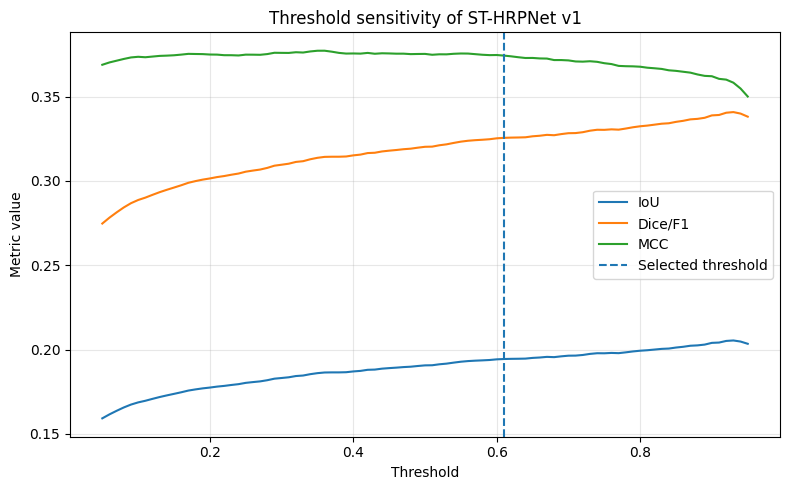

Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\figures\threshold_sensitivity_metrics.png


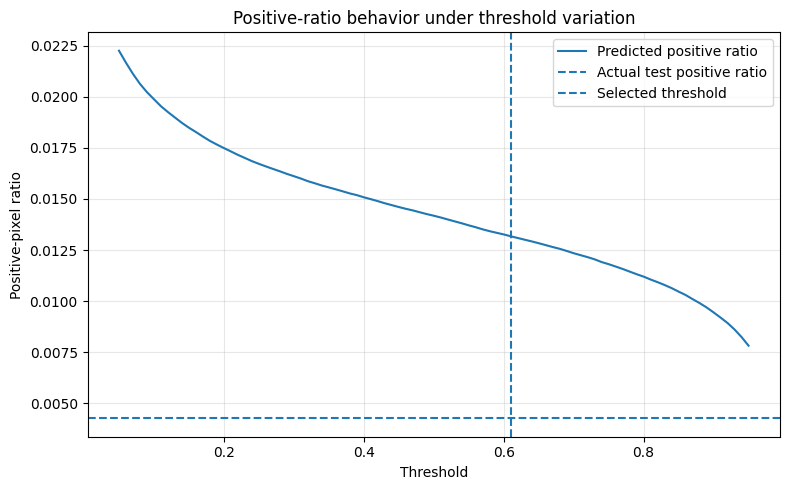

Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\figures\threshold_sensitivity_positive_ratio.png


In [14]:
# ============================================================
# 10. THRESHOLD SENSITIVITY ANALYSIS
# ============================================================

if RUN_THRESHOLD_SENSITIVITY:
    rows = []
    for th in THRESHOLD_VALUES:
        m_val = binary_metrics_np(y_val, st_val_prob, threshold=float(th))
        m_test = binary_metrics_np(y_test, st_test_prob, threshold=float(th))
        rows.append({
            "threshold": float(th),
            "val_iou": m_val["iou"],
            "val_dice_f1": m_val["dice_f1"],
            "val_precision": m_val["precision"],
            "val_recall": m_val["recall"],
            "val_mcc": m_val["mcc"],
            "val_predicted_positive_ratio": m_val["predicted_positive_ratio"],
            "test_iou": m_test["iou"],
            "test_dice_f1": m_test["dice_f1"],
            "test_precision": m_test["precision"],
            "test_recall": m_test["recall"],
            "test_mcc": m_test["mcc"],
            "test_predicted_positive_ratio": m_test["predicted_positive_ratio"],
        })

    threshold_df = pd.DataFrame(rows)
    threshold_path = TABLES_DIR / "threshold_sensitivity_STHRPNet_fair.csv"
    threshold_df.to_csv(threshold_path, index=False)
    display(threshold_df.head())
    print("Saved:", threshold_path)

    plt.figure(figsize=(8, 5))
    plt.plot(threshold_df["threshold"], threshold_df["test_iou"], label="IoU")
    plt.plot(threshold_df["threshold"], threshold_df["test_dice_f1"], label="Dice/F1")
    plt.plot(threshold_df["threshold"], threshold_df["test_mcc"], label="MCC")
    plt.axvline(main_metrics["selected_threshold_from_validation"], linestyle="--", label="Selected threshold")
    plt.xlabel("Threshold")
    plt.ylabel("Metric value")
    plt.title("Threshold sensitivity of ST-HRPNet v1")
    plt.legend()
    plt.grid(True, alpha=0.3)
    fig_path = FIGURES_DIR / "threshold_sensitivity_metrics.png"
    plt.tight_layout()
    plt.savefig(fig_path, dpi=300)
    plt.show()
    print("Saved:", fig_path)

    actual_ratio_test = float(np.mean(y_test))
    plt.figure(figsize=(8, 5))
    plt.plot(threshold_df["threshold"], threshold_df["test_predicted_positive_ratio"], label="Predicted positive ratio")
    plt.axhline(actual_ratio_test, linestyle="--", label="Actual test positive ratio")
    plt.axvline(main_metrics["selected_threshold_from_validation"], linestyle="--", label="Selected threshold")
    plt.xlabel("Threshold")
    plt.ylabel("Positive-pixel ratio")
    plt.title("Positive-ratio behavior under threshold variation")
    plt.legend()
    plt.grid(True, alpha=0.3)
    fig_path = FIGURES_DIR / "threshold_sensitivity_positive_ratio.png"
    plt.tight_layout()
    plt.savefig(fig_path, dpi=300)
    plt.show()
    print("Saved:", fig_path)
else:
    print("Threshold sensitivity skipped.")


In [15]:
# ============================================================
# 11. FAIR ABLATION HELPERS
# ============================================================

def make_random_patches(X_arr, y_arr, n_patches, patch_size=PATCH_SIZE):
    Xp, yp = [], []
    n, t, h, w, c = X_arr.shape
    for _ in tqdm(range(int(n_patches)), desc="Random patches"):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)
        Xp.append(X_arr[idx, :, top:top + patch_size, left:left + patch_size, :])
        yp.append(y_arr[idx, top:top + patch_size, left:left + patch_size, :])
    return np.asarray(Xp, dtype=np.float32), np.asarray(yp, dtype=np.float32)


def ensure_patch_data():
    global X_train_patch, y_train_patch, X_val_patch, y_val_patch

    if all(v in globals() for v in ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"]):
        print("Patch-balanced data already in memory.")
        return

    files = {name: CHECKPOINT_DIR / f"{name}.npy" for name in ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"]}
    if all(p.exists() for p in files.values()):
        X_train_patch = np.load(files["X_train_patch"])
        y_train_patch = np.load(files["y_train_patch"])
        X_val_patch = np.load(files["X_val_patch"])
        y_val_patch = np.load(files["y_val_patch"])
        print("Patch-balanced checkpoints loaded.")
        return

    print("Patch-balanced arrays belum ada. Membuat fallback random patch.")
    print("Untuk paper, lebih baik gunakan patch-balanced arrays asli dari notebook utama.")
    n_train = globals().get("N_TRAIN_PATCHES", 1800)
    n_val = globals().get("N_VAL_PATCHES", 450)
    X_train_patch, y_train_patch = make_random_patches(X_train, y_train, n_train, PATCH_SIZE)
    X_val_patch, y_val_patch = make_random_patches(X_val, y_val, n_val, PATCH_SIZE)

    for name in ["X_train_patch", "y_train_patch", "X_val_patch", "y_val_patch"]:
        np.save(CHECKPOINT_DIR / f"{name}.npy", globals()[name])


def train_model_safe(model, train_data, val_data, name, epochs=EPOCHS_ABLATION):
    model_dir = MODELS_DIR / name
    model_dir.mkdir(parents=True, exist_ok=True)

    ckpt_path = model_dir / f"{name}_best.weights.h5"
    history_path = TABLES_DIR / f"{name}_history.csv"
    log_path = TABLES_DIR / f"{name}_training_log.csv"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(ckpt_path),
            monitor="val_iou_coef",
            mode="max",
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_iou_coef",
            mode="max",
            patience=ABLATION_PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1,
        ),
        keras.callbacks.CSVLogger(str(log_path), append=False),
    ]

    start = time.time()
    hist = model.fit(
        train_data,
        validation_data=val_data,
        epochs=int(epochs),
        callbacks=callbacks,
        verbose=1,
    )
    elapsed = time.time() - start

    hist_df = pd.DataFrame(hist.history)
    hist_df["epoch"] = np.arange(1, len(hist_df) + 1)
    hist_df["training_time_seconds_total"] = elapsed
    hist_df.to_csv(history_path, index=False)

    if ckpt_path.exists():
        model.load_weights(str(ckpt_path))

    print("Training done:", name)
    print("Weights:", ckpt_path)
    return model, hist, model_dir


Patch-balanced data already in memory.


Random patches: 100%|██████████| 450/450 [00:00<?, ?it/s]


Loading existing ablation weights: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\models\A_RandomPatch_WBCE_Dice_NoFP\A_RandomPatch_WBCE_Dice_NoFP_best.weights.h5
Ablation A skipped/failed: Cannot assign value to variable ' enc1_sepconv1/pointwise_kernel:0': Shape mismatch.The variable shape (1, 1, 4, 24), and the assigned value shape (1, 1, 4, 16) are incompatible.
Loading existing ablation weights: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\models\B_PatchBalanced_WBCE_Dice_NoFP\B_PatchBalanced_WBCE_Dice_NoFP_best.weights.h5
Ablation B skipped/failed: Cannot assign value to variable ' enc1_sepconv1/pointwise_kernel:0': Shape mismatch.The variable shape (1, 1, 4, 24), and the assigned value shape (1, 1, 4, 16) are incompatible.
Loading existing ablation weights: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\models\C_PatchBalanced_FPaware\C_PatchBalanced_FPaware_best.weights.

,model,input_type,selected_threshold_from_validation,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,pr_auc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn
0,Full_STHRPNet_PatchBalanced_FPaware_FixedThres...,sequence,0.50,0.50,0.190670,0.320274,0.208372,0.691784,0.988725,0.011275,0.987457,0.840255,0.375353,0.239467,0.004272,0.014182,4067,15451,1812,1354926
1,Full_STHRPNet_PatchBalanced_FPaware,sequence,0.61,0.61,0.194439,0.325574,0.215562,0.664909,0.989620,0.010380,0.988233,0.827264,0.374356,0.239467,0.004272,0.013176,3909,14225,1970,1356152


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\fair_ablation_study_results.csv


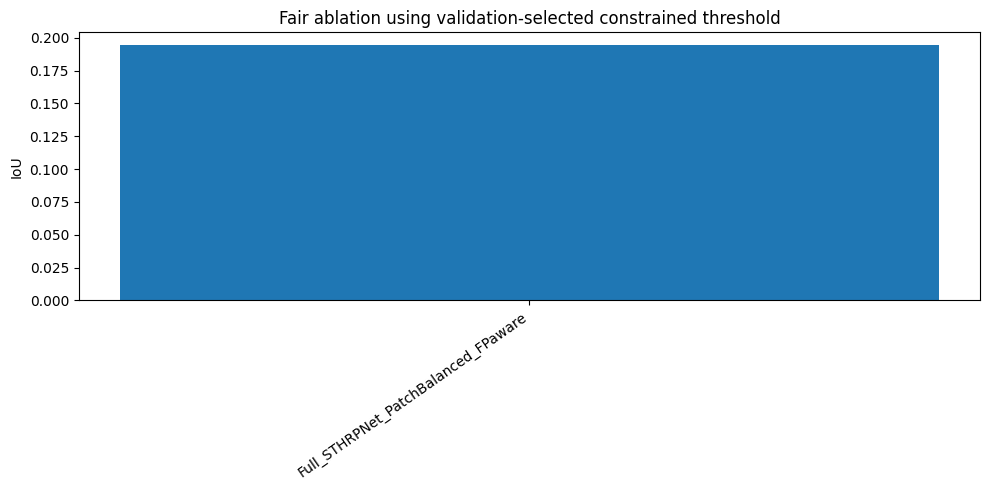

Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\figures\fair_ablation_iou.png


In [16]:
# ============================================================
# 12. FAIR ABLATION STUDY
# ============================================================

def build_or_load_ablation_model(variant_name, loss_fn, train_ds=None, val_ds=None):
    model_dir = MODELS_DIR / variant_name
    weights_path = model_dir / f"{variant_name}_best.weights.h5"

    model = build_st_hrpnet_v1_patchbalanced()
    model = compile_model_with_loss(model, loss_fn=loss_fn, lr=1e-4)

    if weights_path.exists() and not RETRAIN_ABLATIONS:
        print("Loading existing ablation weights:", weights_path)
        model.load_weights(str(weights_path))
        return model

    if not TRAIN_MISSING_ABLATIONS:
        raise FileNotFoundError(f"Weights ablation belum ada dan TRAIN_MISSING_ABLATIONS=False: {weights_path}")

    if train_ds is None or val_ds is None:
        raise RuntimeError("train_ds dan val_ds wajib tersedia untuk training ablation.")

    model, hist, model_dir = train_model_safe(model, train_ds, val_ds, variant_name, epochs=EPOCHS_ABLATION)
    return model


def evaluate_ablation_variant(model, model_name, input_type="sequence"):
    metrics, metrics_05, th_df, val_prob, test_prob = evaluate_model_fair(
        model, model_name, input_type=input_type, force_predict=False
    )
    metrics["ablation_setting"] = model_name
    metrics_05["ablation_setting"] = model_name + "_fixed_0_5"
    return metrics, metrics_05


if RUN_FAIR_ABLATION:
    ensure_patch_data()

    n_train_patches = len(X_train_patch)
    n_val_patches = len(X_val_patch)

    X_train_random_patch, y_train_random_patch = make_random_patches(X_train, y_train, n_train_patches, PATCH_SIZE)
    X_val_random_patch, y_val_random_patch = make_random_patches(X_val, y_val, n_val_patches, PATCH_SIZE)

    train_random_ds = make_dataset(X_train_random_patch, y_train_random_patch, shuffle=True)
    val_random_ds = make_dataset(X_val_random_patch, y_val_random_patch, shuffle=False)

    train_balanced_ds = make_dataset(X_train_patch, y_train_patch, shuffle=True)
    val_balanced_ds = make_dataset(X_val_patch, y_val_patch, shuffle=False)

    ablation_rows = [main_metrics_05, main_metrics]

    try:
        model_A = build_or_load_ablation_model("A_RandomPatch_WBCE_Dice_NoFP", "no_fp", train_random_ds, val_random_ds)
        mA, mA05 = evaluate_ablation_variant(model_A, "A_RandomPatch_WBCE_Dice_NoFP")
        ablation_rows.extend([mA05, mA])
    except Exception as e:
        print("Ablation A skipped/failed:", e)

    try:
        model_B = build_or_load_ablation_model("B_PatchBalanced_WBCE_Dice_NoFP", "no_fp", train_balanced_ds, val_balanced_ds)
        mB, mB05 = evaluate_ablation_variant(model_B, "B_PatchBalanced_WBCE_Dice_NoFP")
        ablation_rows.extend([mB05, mB])
    except Exception as e:
        print("Ablation B skipped/failed:", e)

    try:
        model_C = build_or_load_ablation_model("C_PatchBalanced_FPaware", "with_fp", train_balanced_ds, val_balanced_ds)
        mC, mC05 = evaluate_ablation_variant(model_C, "C_PatchBalanced_FPaware")
        ablation_rows.extend([mC05, mC])
    except Exception as e:
        print("Ablation C skipped/failed:", e)

    ablation_df = pd.DataFrame(ablation_rows)

    preferred_cols = [
        "model", "ablation_setting", "input_type", "selected_threshold_from_validation",
        "threshold", "iou", "dice_f1", "precision", "recall", "specificity", "fpr",
        "accuracy", "balanced_accuracy", "mcc", "pr_auc",
        "actual_positive_ratio", "predicted_positive_ratio", "tp", "fp", "fn", "tn"
    ]
    existing_cols = [c for c in preferred_cols if c in ablation_df.columns]
    other_cols = [c for c in ablation_df.columns if c not in existing_cols]
    ablation_df = ablation_df[existing_cols + other_cols]

    ablation_path = TABLES_DIR / "fair_ablation_study_results.csv"
    ablation_df.to_csv(ablation_path, index=False)
    display(ablation_df)
    print("Saved:", ablation_path)

    plot_df = ablation_df[~ablation_df["model"].astype(str).str.contains("FixedThreshold", na=False)].copy()
    if not plot_df.empty:
        plt.figure(figsize=(10, 5))
        x = np.arange(len(plot_df))
        plt.bar(x, plot_df["iou"])
        plt.xticks(x, plot_df["model"], rotation=35, ha="right")
        plt.ylabel("IoU")
        plt.title("Fair ablation using validation-selected constrained threshold")
        plt.tight_layout()
        fig_path = FIGURES_DIR / "fair_ablation_iou.png"
        plt.savefig(fig_path, dpi=300)
        plt.show()
        print("Saved:", fig_path)
else:
    print("Fair ablation skipped.")


## 12B. FINAL MIXEDPATCH ABLATION AND TITLE DECISION

Cell ini adalah eksperimen final tambahan.  
Tujuannya menguji apakah strategi **mixed patch learning** lebih stabil daripada random patch penuh dan patch-balanced penuh.

Varian final:

**D = ST-HRPNet + MixedPatch 50% random + 50% positive-centered + FP-aware loss**

Keputusan paper otomatis:
- Jika D terbaik atau sangat dekat dengan A, judul tetap memakai **imbalance-aware spatiotemporal deep learning framework**.
- Jika A tetap jauh lebih baik, judul disesuaikan menjadi **spatiotemporal deep learning framework** tanpa menonjolkan imbalance-aware sebagai klaim utama.

main_metrics sudah tersedia.
Loading existing MixedPatch cache...
Mixed train: (1800, 4, 128, 128, 4) (1800, 128, 128, 1) positive_ratio= 0.005428975448012352
Mixed val  : (450, 4, 128, 128, 4) (450, 128, 128, 1) positive_ratio= 0.0067430282942950726


,split,n_patches,positive_pixel_ratio,positive_fraction_setting
0,train_mixed,1800,0.005429,0.5
1,validation_mixed,450,0.006743,0.5


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\mixedpatch_dataset_summary.csv
Loading existing D weights: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\models\D_MixedPatch50Random50Positive_FPaware\D_MixedPatch50Random50Positive_FPaware_best.weights.h5


D MixedPatch model ready.
Loaded prediction cache: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\cache\D_MixedPatch50Random50Positive_FPaware_validation_prob.npy
Loaded prediction cache: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\cache\D_MixedPatch50Random50Positive_FPaware_test_prob.npy


,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,...,fp,fn,tn,model,selected_threshold_from_validation,pr_auc,input_type,ablation_setting,patch_strategy,loss_setting
0,0.50,0.387971,0.559048,0.616615,0.511311,0.998636,0.001364,0.996554,0.754974,0.559797,...,1869,2873,1368508,D_MixedPatch50Random50Positive_FPaware_FixedTh...,0.50,0.556532,sequence,D_MixedPatch50Random50Positive_FPaware_fixed_0_5,50% random + 50% positive-centered,WBCE + Dice + FP-aware
1,0.05,0.442038,0.613074,0.572652,0.659636,0.997888,0.002112,0.996443,0.828762,0.612839,...,2894,2001,1367483,D_MixedPatch50Random50Positive_FPaware,0.05,0.556532,sequence,D_MixedPatch50Random50Positive_FPaware,50% random + 50% positive-centered,WBCE + Dice + FP-aware


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\D_mixedpatch_final_results.csv


,model,ablation_setting,patch_strategy,loss_setting,input_type,selected_threshold_from_validation,threshold,iou,dice_f1,precision,...,accuracy,balanced_accuracy,mcc,pr_auc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn
0,Full_STHRPNet_PatchBalanced_FPaware_FixedThres...,NaN,NaN,NaN,sequence,0.50,0.50,0.190670,0.320274,0.208372,...,0.987457,0.840255,0.375353,0.239467,0.004272,0.014182,4067,15451,1812,1354926
1,Full_STHRPNet_PatchBalanced_FPaware,NaN,NaN,NaN,sequence,0.61,0.61,0.194439,0.325574,0.215562,...,0.988233,0.827264,0.374356,0.239467,0.004272,0.013176,3909,14225,1970,1356152
2,D_MixedPatch50Random50Positive_FPaware_FixedTh...,D_MixedPatch50Random50Positive_FPaware_fixed_0_5,50% random + 50% positive-centered,WBCE + Dice + FP-aware,sequence,0.50,0.50,0.387971,0.559048,0.616615,...,0.996554,0.754974,0.559797,0.556532,0.004272,0.003542,3006,1869,2873,1368508
3,D_MixedPatch50Random50Positive_FPaware,D_MixedPatch50Random50Positive_FPaware,50% random + 50% positive-centered,WBCE + Dice + FP-aware,sequence,0.05,0.05,0.442038,0.613074,0.572652,...,0.996443,0.828762,0.612839,0.556532,0.004272,0.004921,3878,2894,2001,1367483


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\FINAL_clean_ablation_with_mixedpatch.csv
FINAL DECISION
Best model by IoU: D_MixedPatch50Random50Positive_FPaware
Best IoU: 0.442038071350256
D MixedPatch IoU: 0.442038071350256
A RandomPatch IoU: nan
Decision: KEEP_IMBALANCE_AWARE_TITLE
Recommended title:
Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework

Novelty position:
AMAN: mixed imbalance-aware patch learning dapat dipertahankan sebagai komponen utama, karena D menjadi terbaik atau sangat dekat dengan random patch sambil menjaga distribusi positif lebih realistis.

Saved:
- D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\FINAL_clean_ablation_with_mixedpatch.csv
- D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\FINAL_title_and_novelty_decision.json
- D:\RISETKOLABORASI\

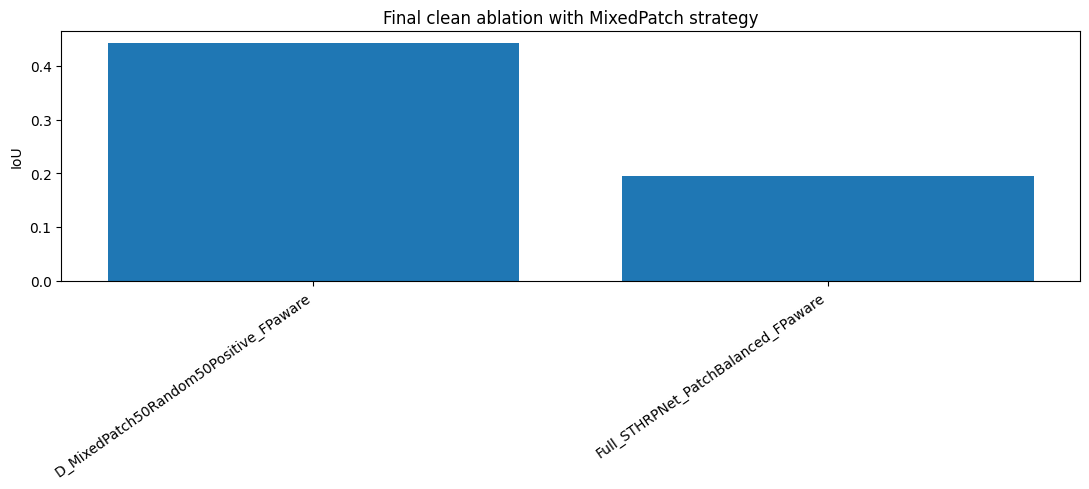

Saved figure: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\figures\FINAL_clean_ablation_with_mixedpatch_iou.png


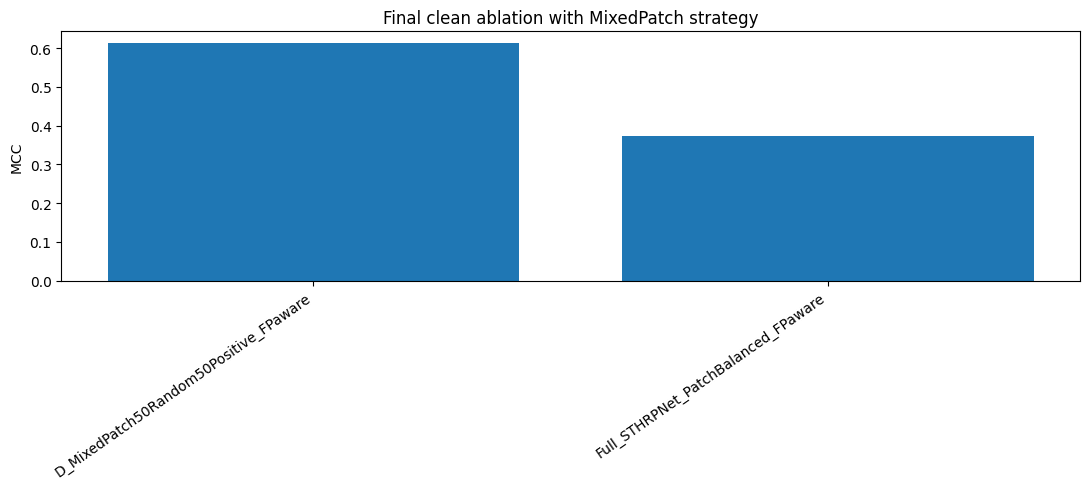

Saved figure: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\figures\FINAL_clean_ablation_with_mixedpatch_mcc.png


In [17]:
# ============================================================
# 12B. FINAL MIXEDPATCH ABLATION AND TITLE DECISION
# ============================================================

# Jalankan cell ini setelah:
# Cell 5 dataset integrity
# Cell 6 metrics
# Cell 7 exact architecture
# Cell 8B load st_model
# Cell 9 main model evaluation
# Cell 11 ablation helpers
# Cell 12 fair ablation, jika A/B/C sudah ada.
#
# Jika Cell 12 belum dijalankan, cell ini tetap bisa melatih D,
# tetapi keputusan final paling kuat jika A/B/C sudah tersedia di fair_ablation_study_results.csv.

import gc
import json
from pathlib import Path

# ------------------------------------------------------------
# 12B.1 Safety guard
# ------------------------------------------------------------

BASE_FILTERS = 24
LEARNING_RATE = 7e-4

required_vars_12b = [
    "X_train", "y_train", "X_val", "y_val", "X_test", "y_test",
    "build_st_hrpnet_v1_patchbalanced",
    "compile_model_with_loss",
    "make_dataset",
    "evaluate_model_fair",
    "binary_metrics_np",
    "pr_auc_score_np",
]

missing_12b = [v for v in required_vars_12b if v not in globals()]
if missing_12b:
    raise RuntimeError(
        "Belum bisa menjalankan 12B. Variabel/fungsi berikut belum tersedia: "
        + ", ".join(missing_12b)
        + ". Jalankan cell 5, 6, 7, 8B, 9, dan 11 terlebih dahulu."
    )

# Pastikan arsitektur builder adalah versi exact, bukan fallback lama.
probe_model = build_st_hrpnet_v1_patchbalanced(
    seq_len=SEQ_LEN,
    n_channels=len(INPUT_PRODUCTS),
    base=BASE_FILTERS,
)
probe_layer_names = [layer.name for layer in probe_model.layers]
if ("enc1_sepconv1" not in probe_layer_names) or ("hrp_mask" not in probe_layer_names):
    raise RuntimeError(
        "Builder ST-HRPNet belum exact. Jalankan ulang Cell 7 EXACT ST-HRPNET BUILDER, "
        "pastikan BASE_FILTERS=24, lalu ulangi Cell 12B."
    )
del probe_model
gc.collect()

try:
    tf.keras.backend.clear_session()
except Exception:
    pass

# ------------------------------------------------------------
# 12B.2 Ensure main metrics exist
# ------------------------------------------------------------

if ("main_metrics" not in globals()) or ("main_metrics_05" not in globals()):
    print("main_metrics belum tersedia. Membuat evaluasi model utama terlebih dahulu...")

    if "st_model" not in globals():
        raise RuntimeError(
            "st_model belum tersedia. Jalankan Cell 8B FORCE LOAD ST_MODEL sebelum 12B."
        )

    main_metrics, main_metrics_05, main_th_df, st_val_prob, st_test_prob = evaluate_model_fair(
        st_model,
        "Full_STHRPNet_PatchBalanced_FPaware",
        input_type="sequence",
        force_predict=False,
    )

    main_eval_df = pd.DataFrame([main_metrics_05, main_metrics])
    main_eval_path = TABLES_DIR / "main_model_re_evaluation_fair_threshold.csv"
    main_eval_df.to_csv(main_eval_path, index=False)
    print("Main metrics created:", main_eval_path)
else:
    print("main_metrics sudah tersedia.")

# ------------------------------------------------------------
# 12B.3 Mixed patch sampler
# ------------------------------------------------------------

def make_mixed_patches(
    X_arr,
    y_arr,
    n_patches,
    patch_size=PATCH_SIZE,
    positive_fraction=0.50,
    min_positive_pixels=1,
    seed=SEED,
):
    """
    MixedPatch:
    - sebagian patch random untuk menjaga distribusi background alami;
    - sebagian patch dipusatkan pada piksel HRP positif agar rare pattern tetap dipelajari.
    """
    rng = np.random.default_rng(seed)

    X_arr = np.asarray(X_arr, dtype=np.float32)
    y_arr = np.asarray(y_arr, dtype=np.float32)

    n, t, h, w, c = X_arr.shape
    n_patches = int(n_patches)
    n_positive = int(round(n_patches * positive_fraction))
    n_random = n_patches - n_positive

    Xp, yp = [], []
    patch_records = []

    def append_patch(idx, top, left, patch_type):
        x_patch = X_arr[idx, :, top:top + patch_size, left:left + patch_size, :]
        y_patch = y_arr[idx, top:top + patch_size, left:left + patch_size, :]
        Xp.append(x_patch)
        yp.append(y_patch)
        patch_records.append({
            "source_index": int(idx),
            "top": int(top),
            "left": int(left),
            "patch_type": patch_type,
            "positive_ratio": float(np.mean(y_patch)),
            "positive_pixels": int(np.count_nonzero(y_patch >= 0.5)),
        })

    # 50% random patches
    for _ in tqdm(range(n_random), desc="MixedPatch random"):
        idx = int(rng.integers(0, n))
        top = int(rng.integers(0, h - patch_size + 1))
        left = int(rng.integers(0, w - patch_size + 1))
        append_patch(idx, top, left, "random")

    # 50% positive-centered patches
    positive_indices = []
    for idx in range(n):
        mask = y_arr[idx, ..., 0] if y_arr.ndim == 4 else y_arr[idx]
        if int(np.count_nonzero(mask >= 0.5)) >= int(min_positive_pixels):
            positive_indices.append(idx)

    if len(positive_indices) == 0:
        print("WARNING: Tidak ada mask positif. Positive-centered diganti random.")
        for _ in tqdm(range(n_positive), desc="MixedPatch positive fallback-random"):
            idx = int(rng.integers(0, n))
            top = int(rng.integers(0, h - patch_size + 1))
            left = int(rng.integers(0, w - patch_size + 1))
            append_patch(idx, top, left, "positive_fallback_random")
    else:
        for _ in tqdm(range(n_positive), desc="MixedPatch positive-centered"):
            idx = int(rng.choice(positive_indices))
            mask = y_arr[idx, ..., 0] if y_arr.ndim == 4 else y_arr[idx]
            coords = np.argwhere(mask >= 0.5)

            # Pilih salah satu piksel HRP sebagai anchor.
            cy, cx = coords[int(rng.integers(0, len(coords)))]

            # Jitter agar tidak terlalu selalu berada tepat di tengah.
            jitter_y = int(rng.integers(-patch_size // 4, patch_size // 4 + 1))
            jitter_x = int(rng.integers(-patch_size // 4, patch_size // 4 + 1))

            top = int(np.clip(cy - patch_size // 2 + jitter_y, 0, h - patch_size))
            left = int(np.clip(cx - patch_size // 2 + jitter_x, 0, w - patch_size))

            append_patch(idx, top, left, "positive_centered")

    Xp = np.asarray(Xp, dtype=np.float32)
    yp = np.asarray(yp, dtype=np.float32)
    meta_patch = pd.DataFrame(patch_records)

    # Shuffle final mixed patches
    order = rng.permutation(len(Xp))
    Xp = Xp[order]
    yp = yp[order]
    meta_patch = meta_patch.iloc[order].reset_index(drop=True)

    return Xp, yp, meta_patch


# ------------------------------------------------------------
# 12B.4 Build/load MixedPatch dataset
# ------------------------------------------------------------

D_VARIANT_NAME = "D_MixedPatch50Random50Positive_FPaware"
D_POSITIVE_FRACTION = 0.50
D_EPOCHS = 50
D_PATIENCE = 12

# Jumlah patch disamakan dengan patch-balanced kalau tersedia.
if "X_train_patch" in globals():
    N_TRAIN_MIXED = len(X_train_patch)
else:
    N_TRAIN_MIXED = int(globals().get("N_TRAIN_PATCHES", 1800))

if "X_val_patch" in globals():
    N_VAL_MIXED = len(X_val_patch)
else:
    N_VAL_MIXED = int(globals().get("N_VAL_PATCHES", 450))

mixed_cache = CHECKPOINT_DIR / "mixedpatch_v3"
mixed_cache.mkdir(parents=True, exist_ok=True)

X_train_mixed_path = mixed_cache / "X_train_mixed_patch.npy"
y_train_mixed_path = mixed_cache / "y_train_mixed_patch.npy"
X_val_mixed_path = mixed_cache / "X_val_mixed_patch.npy"
y_val_mixed_path = mixed_cache / "y_val_mixed_patch.npy"
meta_train_mixed_path = mixed_cache / "meta_train_mixed_patch.csv"
meta_val_mixed_path = mixed_cache / "meta_val_mixed_patch.csv"

if all(p.exists() for p in [X_train_mixed_path, y_train_mixed_path, X_val_mixed_path, y_val_mixed_path]):
    print("Loading existing MixedPatch cache...")
    X_train_mixed_patch = np.load(X_train_mixed_path)
    y_train_mixed_patch = np.load(y_train_mixed_path)
    X_val_mixed_patch = np.load(X_val_mixed_path)
    y_val_mixed_patch = np.load(y_val_mixed_path)

    meta_train_mixed = pd.read_csv(meta_train_mixed_path) if meta_train_mixed_path.exists() else pd.DataFrame()
    meta_val_mixed = pd.read_csv(meta_val_mixed_path) if meta_val_mixed_path.exists() else pd.DataFrame()
else:
    print("Creating final MixedPatch dataset...")
    X_train_mixed_patch, y_train_mixed_patch, meta_train_mixed = make_mixed_patches(
        X_train,
        y_train,
        n_patches=N_TRAIN_MIXED,
        patch_size=PATCH_SIZE,
        positive_fraction=D_POSITIVE_FRACTION,
        seed=SEED + 101,
    )

    X_val_mixed_patch, y_val_mixed_patch, meta_val_mixed = make_mixed_patches(
        X_val,
        y_val,
        n_patches=N_VAL_MIXED,
        patch_size=PATCH_SIZE,
        positive_fraction=D_POSITIVE_FRACTION,
        seed=SEED + 202,
    )

    np.save(X_train_mixed_path, X_train_mixed_patch)
    np.save(y_train_mixed_path, y_train_mixed_patch)
    np.save(X_val_mixed_path, X_val_mixed_patch)
    np.save(y_val_mixed_path, y_val_mixed_patch)
    meta_train_mixed.to_csv(meta_train_mixed_path, index=False)
    meta_val_mixed.to_csv(meta_val_mixed_path, index=False)

print("Mixed train:", X_train_mixed_patch.shape, y_train_mixed_patch.shape, "positive_ratio=", float(np.mean(y_train_mixed_patch)))
print("Mixed val  :", X_val_mixed_patch.shape, y_val_mixed_patch.shape, "positive_ratio=", float(np.mean(y_val_mixed_patch)))

mixed_summary = pd.DataFrame([
    {
        "split": "train_mixed",
        "n_patches": len(X_train_mixed_patch),
        "positive_pixel_ratio": float(np.mean(y_train_mixed_patch)),
        "positive_fraction_setting": D_POSITIVE_FRACTION,
    },
    {
        "split": "validation_mixed",
        "n_patches": len(X_val_mixed_patch),
        "positive_pixel_ratio": float(np.mean(y_val_mixed_patch)),
        "positive_fraction_setting": D_POSITIVE_FRACTION,
    },
])
mixed_summary_path = TABLES_DIR / "mixedpatch_dataset_summary.csv"
mixed_summary.to_csv(mixed_summary_path, index=False)
display(mixed_summary)
print("Saved:", mixed_summary_path)

# ------------------------------------------------------------
# 12B.5 Train/load D model
# ------------------------------------------------------------

train_mixed_ds = make_dataset(X_train_mixed_patch, y_train_mixed_patch, shuffle=True)
val_mixed_ds = make_dataset(X_val_mixed_patch, y_val_mixed_patch, shuffle=False)

D_model_dir = MODELS_DIR / D_VARIANT_NAME
D_model_dir.mkdir(parents=True, exist_ok=True)
D_weights_path = D_model_dir / f"{D_VARIANT_NAME}_best.weights.h5"

if D_weights_path.exists() and not RETRAIN_ABLATIONS:
    print("Loading existing D weights:", D_weights_path)
    model_D = build_st_hrpnet_v1_patchbalanced(
        seq_len=SEQ_LEN,
        n_channels=len(INPUT_PRODUCTS),
        base=BASE_FILTERS,
    )
    model_D = compile_model_with_loss(model_D, loss_fn="with_fp", lr=LEARNING_RATE)
    model_D.load_weights(str(D_weights_path))
else:
    print("Training final D MixedPatch model...")
    old_patience = globals().get("ABLATION_PATIENCE", 10)
    ABLATION_PATIENCE = D_PATIENCE

    model_D = build_st_hrpnet_v1_patchbalanced(
        seq_len=SEQ_LEN,
        n_channels=len(INPUT_PRODUCTS),
        base=BASE_FILTERS,
    )
    model_D = compile_model_with_loss(model_D, loss_fn="with_fp", lr=LEARNING_RATE)

    model_D, hist_D, model_dir_D = train_model_safe(
        model_D,
        train_mixed_ds,
        val_mixed_ds,
        D_VARIANT_NAME,
        epochs=D_EPOCHS,
    )

    ABLATION_PATIENCE = old_patience

print("D MixedPatch model ready.")

# ------------------------------------------------------------
# 12B.6 Evaluate D with the same full-image validation-threshold protocol
# ------------------------------------------------------------

D_metrics, D_metrics_05, D_th_df, D_val_prob, D_test_prob = evaluate_model_fair(
    model_D,
    D_VARIANT_NAME,
    input_type="sequence",
    force_predict=False,
)

D_metrics["ablation_setting"] = D_VARIANT_NAME
D_metrics["patch_strategy"] = "50% random + 50% positive-centered"
D_metrics["loss_setting"] = "WBCE + Dice + FP-aware"
D_metrics_05["ablation_setting"] = D_VARIANT_NAME + "_fixed_0_5"
D_metrics_05["patch_strategy"] = "50% random + 50% positive-centered"
D_metrics_05["loss_setting"] = "WBCE + Dice + FP-aware"

D_eval_df = pd.DataFrame([D_metrics_05, D_metrics])
D_eval_path = TABLES_DIR / "D_mixedpatch_final_results.csv"
D_eval_df.to_csv(D_eval_path, index=False)
display(D_eval_df)
print("Saved:", D_eval_path)

# ------------------------------------------------------------
# 12B.7 Merge with previous ablation table
# ------------------------------------------------------------

previous_ablation_path = TABLES_DIR / "fair_ablation_study_results.csv"
if previous_ablation_path.exists():
    previous_ablation_df = pd.read_csv(previous_ablation_path)
else:
    print("fair_ablation_study_results.csv belum ada. Membuat tabel dari main metrics saja.")
    previous_ablation_df = pd.DataFrame([main_metrics_05, main_metrics])

final_ablation_df = pd.concat([previous_ablation_df, D_eval_df], ignore_index=True)

# Drop duplicate model rows, keep latest.
if "model" in final_ablation_df.columns:
    final_ablation_df = final_ablation_df.drop_duplicates(subset=["model"], keep="last")

preferred_cols = [
    "model", "ablation_setting", "patch_strategy", "loss_setting",
    "input_type", "selected_threshold_from_validation", "threshold",
    "iou", "dice_f1", "precision", "recall", "specificity", "fpr",
    "accuracy", "balanced_accuracy", "mcc", "pr_auc",
    "actual_positive_ratio", "predicted_positive_ratio", "tp", "fp", "fn", "tn"
]
existing_cols = [c for c in preferred_cols if c in final_ablation_df.columns]
other_cols = [c for c in final_ablation_df.columns if c not in existing_cols]
final_ablation_df = final_ablation_df[existing_cols + other_cols]

final_ablation_path = TABLES_DIR / "FINAL_clean_ablation_with_mixedpatch.csv"
final_ablation_df.to_csv(final_ablation_path, index=False)
display(final_ablation_df)
print("Saved:", final_ablation_path)

# ------------------------------------------------------------
# 12B.8 Final decision and title recommendation
# ------------------------------------------------------------

# Pakai hanya row validation-selected threshold, bukan FixedThreshold.
eval_rows = final_ablation_df[
    ~final_ablation_df["model"].astype(str).str.contains("FixedThreshold", na=False)
].copy()

# Pastikan kolom numeric
for col in ["iou", "dice_f1", "mcc", "pr_auc", "predicted_positive_ratio", "actual_positive_ratio", "fpr", "recall", "precision"]:
    if col in eval_rows.columns:
        eval_rows[col] = pd.to_numeric(eval_rows[col], errors="coerce")

eval_rows = eval_rows.dropna(subset=["iou"]).sort_values("iou", ascending=False).reset_index(drop=True)

best_row = eval_rows.iloc[0].to_dict()
best_model = str(best_row.get("model", "unknown"))
best_iou = float(best_row.get("iou", np.nan))

D_row_df = eval_rows[eval_rows["model"].astype(str) == D_VARIANT_NAME]
if len(D_row_df) > 0:
    D_row = D_row_df.iloc[0].to_dict()
    D_iou = float(D_row.get("iou", np.nan))
else:
    D_row = {}
    D_iou = np.nan

A_row_df = eval_rows[eval_rows["model"].astype(str) == "A_RandomPatch_WBCE_Dice_NoFP"]
if len(A_row_df) > 0:
    A_row = A_row_df.iloc[0].to_dict()
    A_iou = float(A_row.get("iou", np.nan))
else:
    A_row = {}
    A_iou = np.nan

# Title logic
# D boleh dianggap aman jika:
# 1. D adalah terbaik, atau
# 2. D minimal 98% dari A dan lebih realistis dari sisi positive ratio/FPR.
D_close_to_A = False
if not np.isnan(D_iou) and not np.isnan(A_iou) and A_iou > 0:
    D_close_to_A = D_iou >= 0.98 * A_iou

D_is_best = (best_model == D_VARIANT_NAME)

D_ratio_ok = False
if D_row:
    ar = float(D_row.get("actual_positive_ratio", np.nan))
    pr = float(D_row.get("predicted_positive_ratio", np.nan))
    if ar > 0:
        D_ratio_ok = (0.5 * ar <= pr <= 2.0 * ar)

if D_is_best or (D_close_to_A and D_ratio_ok):
    recommended_title = (
        "Himawari-derived heavy rainfall potential segmentation over Indonesia "
        "using an imbalance-aware spatiotemporal deep learning framework"
    )
    novelty_position = (
        "AMAN: mixed imbalance-aware patch learning dapat dipertahankan sebagai komponen utama, "
        "karena D menjadi terbaik atau sangat dekat dengan random patch sambil menjaga distribusi positif lebih realistis."
    )
    paper_decision = "KEEP_IMBALANCE_AWARE_TITLE"
else:
    recommended_title = (
        "Himawari-derived heavy rainfall potential segmentation over Indonesia "
        "using a spatiotemporal deep learning framework"
    )
    novelty_position = (
        "SESUAIKAN: jangan menjadikan imbalance-aware sebagai klaim utama. "
        "Tulis imbalance-aware/mixed patch learning sebagai strategi pelatihan tambahan, "
        "sedangkan kontribusi utama adalah framework spatiotemporal untuk segmentasi HRP Himawari."
    )
    paper_decision = "ADJUST_TITLE_TO_RESULTS"

decision = {
    "paper_decision": paper_decision,
    "recommended_title": recommended_title,
    "novelty_position": novelty_position,
    "best_model_by_iou": best_model,
    "best_iou": best_iou,
    "D_model_iou": D_iou,
    "A_randompatch_iou": A_iou,
    "D_is_best": bool(D_is_best),
    "D_close_to_A_98pct": bool(D_close_to_A),
    "D_ratio_ok": bool(D_ratio_ok),
    "table_used": str(final_ablation_path),
}

decision_json_path = TABLES_DIR / "FINAL_title_and_novelty_decision.json"
with open(decision_json_path, "w", encoding="utf-8") as f:
    json.dump(decision, f, indent=2)

decision_txt_path = TAAC_OUTPUT_DIR / "FINAL_TITLE_DECISION_README.txt"
with open(decision_txt_path, "w", encoding="utf-8") as f:
    f.write("FINAL TITLE AND NOVELTY DECISION\n")
    f.write("=" * 80 + "\n\n")
    for k, v in decision.items():
        f.write(f"{k}: {v}\n")

print("=" * 90)
print("FINAL DECISION")
print("=" * 90)
print("Best model by IoU:", best_model)
print("Best IoU:", best_iou)
print("D MixedPatch IoU:", D_iou)
print("A RandomPatch IoU:", A_iou)
print("Decision:", paper_decision)
print("Recommended title:")
print(recommended_title)
print("\nNovelty position:")
print(novelty_position)
print("\nSaved:")
print("-", final_ablation_path)
print("-", decision_json_path)
print("-", decision_txt_path)
print("=" * 90)

# ------------------------------------------------------------
# 12B.9 Final plot
# ------------------------------------------------------------

if len(eval_rows) > 0:
    plt.figure(figsize=(11, 5))
    x = np.arange(len(eval_rows))
    plt.bar(x, eval_rows["iou"])
    plt.xticks(x, eval_rows["model"], rotation=35, ha="right")
    plt.ylabel("IoU")
    plt.title("Final clean ablation with MixedPatch strategy")
    plt.tight_layout()
    fig_path = FIGURES_DIR / "FINAL_clean_ablation_with_mixedpatch_iou.png"
    plt.savefig(fig_path, dpi=300)
    plt.show()
    print("Saved figure:", fig_path)

    plt.figure(figsize=(11, 5))
    plt.bar(x, eval_rows["mcc"])
    plt.xticks(x, eval_rows["model"], rotation=35, ha="right")
    plt.ylabel("MCC")
    plt.title("Final clean ablation with MixedPatch strategy")
    plt.tight_layout()
    fig_path = FIGURES_DIR / "FINAL_clean_ablation_with_mixedpatch_mcc.png"
    plt.savefig(fig_path, dpi=300)
    plt.show()
    print("Saved figure:", fig_path)


In [22]:
# ============================================================
# 13. OPTIONAL INDEPENDENT PRECIPITATION VALIDATION
# ============================================================

def load_external_precip_mask():
    npy_path = EXTERNAL_PRECIP_DIR / "precip_test_masks_256.npy"
    if not npy_path.exists():
        status = {
            "status": "not_available",
            "message": "No external precipitation mask found. Put precip_test_masks_256.npy in external_precip_validation.",
            "path_checked": str(npy_path),
        }
        with open(TABLES_DIR / "external_precip_validation_status.json", "w", encoding="utf-8") as f:
            json.dump(status, f, indent=2)
        print(status["message"])
        return None

    arr = np.load(npy_path)
    arr = (arr >= 0.5).astype(np.uint8)
    if arr.ndim == 3:
        arr = arr[..., None]
    if arr.shape != y_test.shape:
        raise ValueError(f"External precip mask shape {arr.shape} tidak sama dengan y_test {y_test.shape}.")
    return arr


if RUN_EXTERNAL_PRECIP_VALIDATION:
    precip_mask = load_external_precip_mask()

    if precip_mask is not None:
        selected_th = float(main_metrics["selected_threshold_from_validation"])
        pred_mask = (st_test_prob >= selected_th).astype(np.uint8)

        ext_metrics = binary_metrics_np(precip_mask, pred_mask, threshold=0.5)
        ext_metrics["model"] = "Full_STHRPNet_vs_ExternalPrecipMask"
        ext_metrics["reference"] = "external_precipitation_binary_mask"
        ext_metrics["selected_threshold_from_validation"] = selected_th

        ext_df = pd.DataFrame([ext_metrics])
        ext_path = TABLES_DIR / "external_precip_validation_metrics.csv"
        ext_df.to_csv(ext_path, index=False)
        display(ext_df)
        print("Saved:", ext_path)
else:
    print("External precipitation validation skipped.")


No external precipitation mask found. Put precip_test_masks_256.npy in external_precip_validation.


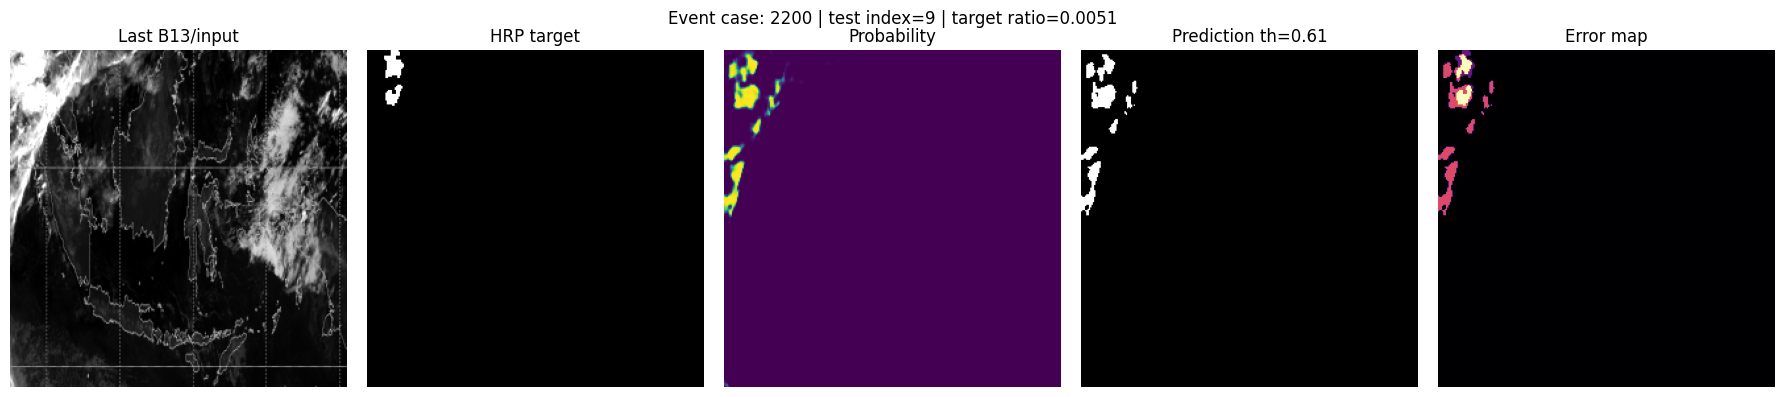

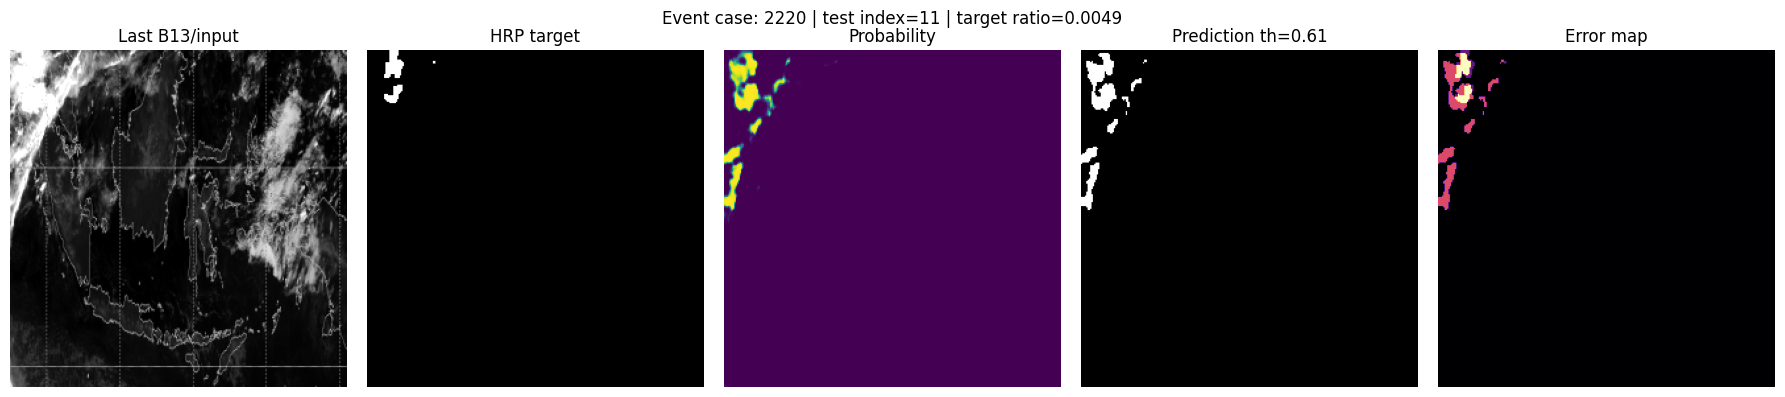

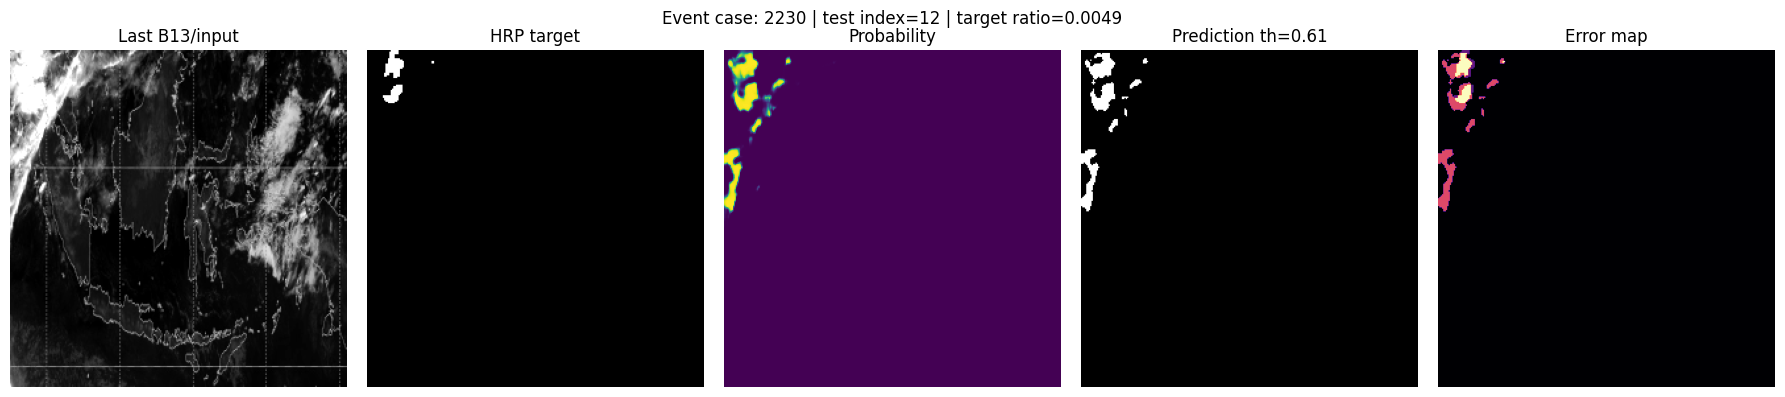

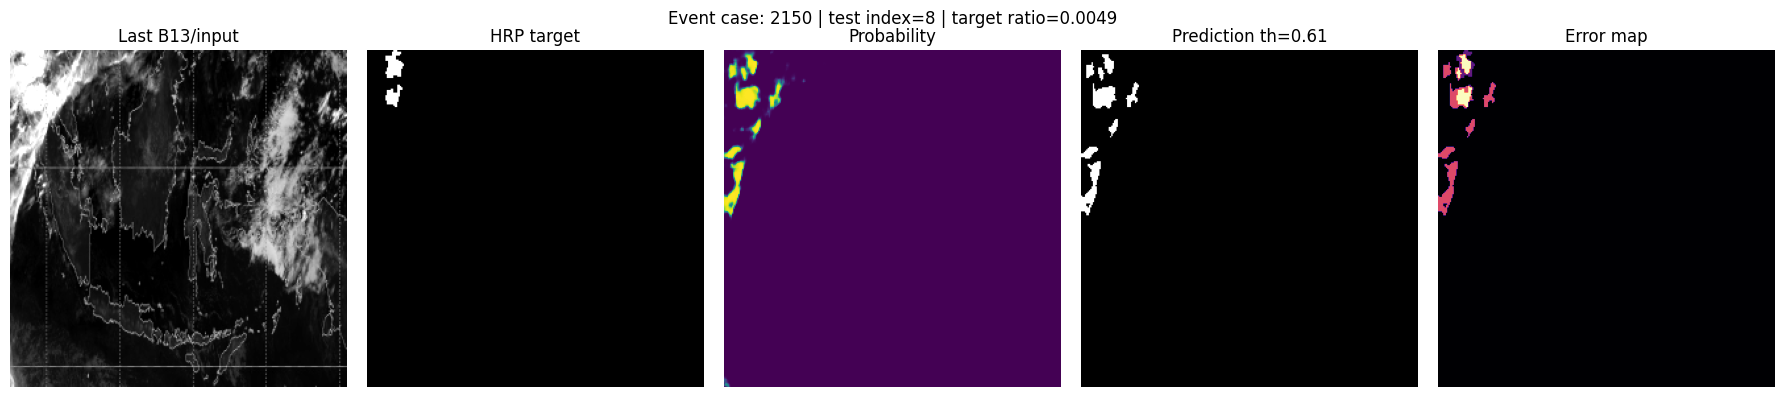

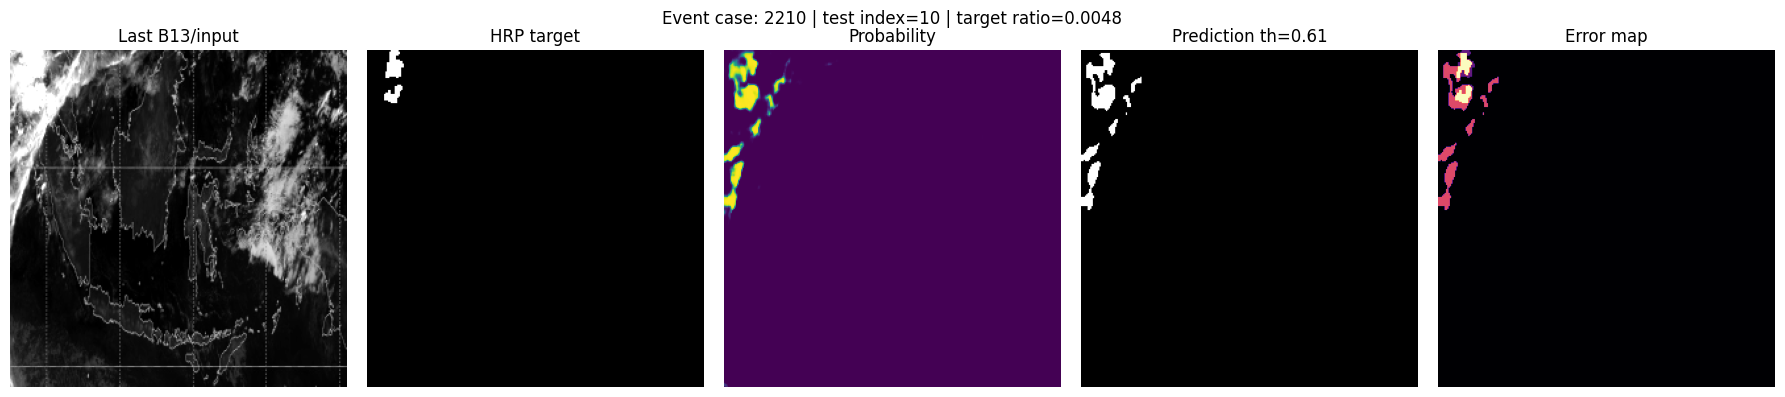

,test_index,time_label,target_positive_ratio,figure_path
0,9,2200,0.005066,D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\...
1,11,2220,0.004944,D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\...
2,12,2230,0.004913,D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\...
3,8,2150,0.004852,D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\...
4,10,2210,0.004791,D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\...


Saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\tables\event_case_selection.csv


In [23]:
# ============================================================
# 14. EVENT-BASED METEOROLOGICAL CASE ANALYSIS
# ============================================================

def select_event_indices(k=5):
    ratios = np.asarray([float(y_test[i].mean()) for i in range(len(y_test))])
    order = np.argsort(-ratios)
    return order[:min(k, len(order))]


def get_time_label(idx):
    if "meta_test" in globals() and isinstance(meta_test, pd.DataFrame) and idx < len(meta_test):
        row = meta_test.iloc[idx]
        for col in ["target_time_code", "time_code", "end_time_code", "time"]:
            if col in row:
                return str(row[col])
    return f"test_index_{idx}"


def visualize_event_case(idx, threshold=None):
    if threshold is None:
        threshold = float(main_metrics["selected_threshold_from_validation"])

    x_last = X_test[idx, -1]
    y_true = y_test[idx, ..., 0] if y_test.ndim == 4 else y_test[idx]
    prob = st_test_prob[idx, ..., 0] if st_test_prob.ndim == 4 else st_test_prob[idx]
    pred = (prob >= threshold).astype(np.uint8)

    b13 = x_last[..., 0]

    error = np.zeros_like(y_true, dtype=np.float32)
    error[(y_true >= 0.5) & (pred == 1)] = 1.0
    error[(y_true < 0.5) & (pred == 1)] = 0.6
    error[(y_true >= 0.5) & (pred == 0)] = 0.3

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))

    axes[0].imshow(b13, cmap="gray")
    axes[0].set_title("Last B13/input")
    axes[0].axis("off")

    axes[1].imshow(y_true, cmap="gray")
    axes[1].set_title("HRP target")
    axes[1].axis("off")

    axes[2].imshow(prob, cmap="viridis")
    axes[2].set_title("Probability")
    axes[2].axis("off")

    axes[3].imshow(pred, cmap="gray")
    axes[3].set_title(f"Prediction th={threshold:.2f}")
    axes[3].axis("off")

    axes[4].imshow(error, cmap="magma")
    axes[4].set_title("Error map")
    axes[4].axis("off")

    time_label = get_time_label(idx)
    fig.suptitle(f"Event case: {time_label} | test index={idx} | target ratio={float(y_true.mean()):.4f}")

    safe_label = re.sub(r"[^A-Za-z0-9_\\-]+", "_", str(time_label))
    out_path = FIGURES_DIR / f"event_case_{idx:03d}_{safe_label}.png"
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()

    return out_path


if RUN_EVENT_CASE_ANALYSIS:
    selected_indices = select_event_indices(k=5)
    event_rows = []

    for idx in selected_indices:
        out_path = visualize_event_case(int(idx))
        event_rows.append({
            "test_index": int(idx),
            "time_label": get_time_label(int(idx)),
            "target_positive_ratio": float(np.mean(y_test[int(idx)])),
            "figure_path": str(out_path),
        })

    event_df = pd.DataFrame(event_rows)
    event_path = TABLES_DIR / "event_case_selection.csv"
    event_df.to_csv(event_path, index=False)
    display(event_df)
    print("Saved:", event_path)
else:
    print("Event case analysis skipped.")


In [24]:
# ============================================================
# 15. EXPORT MANUSCRIPT-READY SUMMARY
# ============================================================

def read_csv_safe(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    return pd.DataFrame()


summary_lines = []
summary_lines.append("# TAAC Re-Experiment V3 Summary")
summary_lines.append("")
summary_lines.append(f"Paper title: {PAPER_TITLE_TAAC}")
summary_lines.append("")

summary_lines.append("## Dataset integrity")
summary_lines.append(integrity_df.to_markdown(index=False))

main_eval_df = read_csv_safe(TABLES_DIR / "main_model_re_evaluation_fair_threshold.csv")
if not main_eval_df.empty:
    summary_lines.append("")
    summary_lines.append("## Main model re-evaluation")
    summary_lines.append(main_eval_df.to_markdown(index=False))

ablation_df = read_csv_safe(TABLES_DIR / "fair_ablation_study_results.csv")
if not ablation_df.empty:
    summary_lines.append("")
    summary_lines.append("## Fair ablation study")
    summary_lines.append(ablation_df.to_markdown(index=False))

threshold_df = read_csv_safe(TABLES_DIR / "threshold_sensitivity_STHRPNet_fair.csv")
if not threshold_df.empty:
    best_row = threshold_df.sort_values("test_iou", ascending=False).head(1)
    summary_lines.append("")
    summary_lines.append("## Threshold sensitivity")
    summary_lines.append("Best test-IoU threshold row:")
    summary_lines.append(best_row.to_markdown(index=False))

ext_df = read_csv_safe(TABLES_DIR / "external_precip_validation_metrics.csv")
if not ext_df.empty:
    summary_lines.append("")
    summary_lines.append("## External precipitation validation")
    summary_lines.append(ext_df.to_markdown(index=False))
else:
    summary_lines.append("")
    summary_lines.append("## External precipitation validation")
    summary_lines.append("No valid external precipitation mask was available. Do not claim independent precipitation validation.")

event_df = read_csv_safe(TABLES_DIR / "event_case_selection.csv")
if not event_df.empty:
    summary_lines.append("")
    summary_lines.append("## Event case figures")
    summary_lines.append(event_df.to_markdown(index=False))

summary_path = TAAC_OUTPUT_DIR / "TAAC_reexperiment_v3_summary.md"
summary_path.write_text("\\n".join(summary_lines), encoding="utf-8")

print("Summary saved:", summary_path)
print("\\n".join(summary_lines[:40]))


Summary saved: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\TAAC_reexperiment_v3_summary.md
# TAAC Re-Experiment V3 Summary\n\nPaper title: Himawari-derived heavy rainfall potential segmentation over Indonesia using an imbalance-aware spatiotemporal deep learning framework\n\n## Dataset integrity\n| split      |   n_sequences | X_shape              | y_shape           |   positive_pixel_ratio |   min_y |   max_y |
|:-----------|--------------:|:---------------------|:------------------|-----------------------:|--------:|--------:|
| train      |            97 | (97, 4, 256, 256, 4) | (97, 256, 256, 1) |             0.00253579 |       0 |       1 |
| validation |            21 | (21, 4, 256, 256, 4) | (21, 256, 256, 1) |             0.00321379 |       0 |       1 |
| test       |            21 | (21, 4, 256, 256, 4) | (21, 256, 256, 1) |             0.00427173 |       0 |       1 |\n\n## Main model re-evaluation\n|   threshold |      iou |   dice_f1

In [25]:
# ============================================================
# 16. FINAL DECISION CHECK
# ============================================================

def final_decision_check():
    issues = []

    test_ratio = float(np.mean(y_test))
    if abs(test_ratio - EXPECTED_TEST_POS_RATIO) > POS_RATIO_TOLERANCE:
        issues.append(
            f"Test positive ratio mismatch: current={test_ratio:.6f}, expected~={EXPECTED_TEST_POS_RATIO:.6f}"
        )

    main_df = read_csv_safe(TABLES_DIR / "main_model_re_evaluation_fair_threshold.csv")
    if main_df.empty:
        issues.append("Main re-evaluation table missing.")
    else:
        row = main_df[~main_df["model"].astype(str).str.contains("FixedThreshold", na=False)].tail(1)
        if len(row) > 0:
            iou = float(row.iloc[0]["iou"])
            mcc = float(row.iloc[0]["mcc"])
            pr = float(row.iloc[0]["predicted_positive_ratio"])
            ar = float(row.iloc[0]["actual_positive_ratio"])
            if iou <= 0:
                issues.append("Main IoU is non-positive.")
            if mcc <= 0:
                issues.append("Main MCC is non-positive.")
            if not (0.5 * ar <= pr <= 2.0 * ar):
                issues.append(f"Predicted positive ratio not within 0.5x-2x actual: pred={pr:.6f}, actual={ar:.6f}")

    ab_df = read_csv_safe(TABLES_DIR / "fair_ablation_study_results.csv")
    if ab_df.empty:
        issues.append("Fair ablation table missing. Bisa ditunda, tetapi novelty model lebih lemah tanpa ablation.")

    ext_df = read_csv_safe(TABLES_DIR / "external_precip_validation_metrics.csv")
    if ext_df.empty:
        print("External precipitation validation not available. Treat it as limitation/future work, not as result.")

    if issues:
        print("=" * 80)
        print("BELUM AMAN UNTUK NARASI HASIL FINAL.")
        print("=" * 80)
        for issue in issues:
            print("-", issue)
    else:
        print("=" * 80)
        print("AMAN UNTUK LANJUT KE PENULISAN RESULTS/DISCUSSION.")
        print("=" * 80)
        print("Gunakan tabel dan figure dari:", TAAC_OUTPUT_DIR)

final_decision_check()


External precipitation validation not available. Treat it as limitation/future work, not as result.
BELUM AMAN UNTUK NARASI HASIL FINAL.
- Test positive ratio mismatch: current=0.004272, expected~=0.025300
- Predicted positive ratio not within 0.5x-2x actual: pred=0.013176, actual=0.004272
